# Relevance Classifier — Prompt Compression with Relevance Maintainer

**Goal.** Long prompts (e.g. RAG prompts stuffed with retrieved documents) are expensive and often mostly noise. A *relevance classifier* scores every chunk of context against the user's question so we can drop the irrelevant chunks and keep only what is needed to answer — compressing the prompt **without losing the relevant information**.

**Plan of this notebook.**
0. Set every tunable hyper-parameter in **one configuration cell**, so the whole notebook can be re-run with other settings (`run_experiments.py` runs 5 combinations).
1. Install and verify the Python libraries we need.
2. Download **HotpotQA** — a multi-hop QA dataset where every question comes with 10 paragraphs, only 2 of which actually matter. That gives us free, human-annotated relevance labels.
3. Use the **whole dataset** (train + validation, 97,852 questions) and split it **80% train / 20% test** by question; 5% of the training questions are held out as a **dev set** for choosing the best model.
4. Turn every question into 10 *(question, paragraph, relevant?)* training pairs.
5. Train a fast **TF-IDF + Logistic Regression** baseline and measure how well it would preserve the relevant paragraphs if used for compression.
6. Export 250 random questions to Excel in a readable form for manual review and note-taking.
7. Rank paragraphs with **BM25** (unsupervised) on the whole dataset.
8. Fine-tune a **MiniLM cross-encoder** that judges relevance by meaning, and compare it with every baseline.
   - **8b.** Start a **sentence-level compressor** (based on the EnComp paper): label every sentence, map tokens to sentences, and build a model that scores the paragraph *and* each sentence in one pass. Training comes in a later step.
9. **End-to-end answer test:** a local LLM (`SmolLM3-3B`) answers from full vs compressed prompts, scored with Exact Match / F1 against tokens saved.
10. **Experiment report:** save every setting, metric and timing of the run to `results/experiments.csv`, and keep only the best MiniLM model across runs.

Every slow cell prints its run time (`⏱ …`). The next cell explains every metric used — accuracy, precision, recall, F1, ROC-AUC, top-k, and the compression metrics.

Hardware: this notebook runs on an **NVIDIA GPU** (CUDA build of PyTorch; developed on an RTX 5070 Ti, 16 GB). Sections 1–8 fall back to the CPU automatically if no GPU is visible; Section 9 requires one.

## How to read the metrics

This notebook answers two questions, and each has its own metrics: **(A)** does the relevance model keep the right paragraphs, and **(B)** does the LLM still answer correctly from the compressed prompt — and how much smaller is that prompt?

### A. Relevance model — is each paragraph relevant or not?

Every (question, paragraph) pair is classified as *relevant* or *irrelevant*. Comparing the prediction with the truth gives four outcomes:

| | truly **relevant** (gold) | truly **irrelevant** (distractor) |
|---|---|---|
| predicted **relevant** → kept | **TP** — needed and kept | **FP** — kept but not needed (wasted tokens) |
| predicted **irrelevant** → dropped | **FN** — needed but dropped (**answer may be lost**) | **TN** — correctly dropped |

| Metric | Formula | Plain meaning | What it tells us about the model |
|---|---|---|---|
| **Accuracy** | (TP + TN) / all pairs | share of pairs classified correctly | **Misleading on its own here:** 80% of paragraphs are distractors, so a model that drops *everything* already scores 80% accuracy while keeping none of the evidence. Always read it next to recall. |
| **Precision** | TP / (TP + FP) | of the paragraphs the model **kept**, how many were really needed | High precision = little wasted context = **more compression**. Low precision means the model keeps distractors "to be safe" and the prompt stays long. |
| **Recall** | TP / (TP + FN) | of the paragraphs that were **needed**, how many the model kept | High recall = the **evidence survives** and the LLM can still answer. For compression this is the more important of the two: dropping a needed paragraph can make the answer impossible, while keeping one extra distractor only costs some tokens. |
| **F1-score** | 2 · P · R / (P + R) | harmonic mean of precision and recall | High only when **both** are high — one number for "keeps the evidence *and* drops the noise". A model cannot score well by keeping everything (precision drops) or dropping everything (recall drops). |
| **ROC-AUC** | P(score of a random relevant paragraph > score of a random distractor) | ranking quality, independent of any threshold | 0.5 = random guessing, 1.0 = every relevant paragraph is ranked above every distractor. It shows whether the model *understands* which paragraph matters more, even before a threshold is chosen. |
| **All gold in top-k** | share of questions whose relevant paragraphs are **all** in the k highest-scored of 10 | the compression metric: "if we keep only k paragraphs, is everything needed still there?" | This is how the model is actually used. k = 2 keeps 20% of the context, so a high top-2 score means strong compression with the evidence intact. |

Precision, recall, F1 and accuracy use a fixed cut-off (probability ≥ 0.5); ROC-AUC and top-k only use the **ranking**, which is what compression relies on.

### B. End-to-end answers — is the answer still correct, and how much was the prompt compressed?

| Metric | Plain meaning | What it tells us |
|---|---|---|
| **EM (Exact Match)** | share of answers identical to the gold answer (after lower-casing and removing punctuation / articles) | strict answer accuracy |
| **Answer F1** | word overlap between predicted and gold answer | partial credit, e.g. "Knox County Airport" vs "Knox County Regional Airport". *Not the same F1 as in part A* — this one compares words of an answer, not kept vs needed paragraphs. |
| **Compression** | full-prompt tokens ÷ compressed-prompt tokens | 4× = the prompt is a quarter of its original size |
| **Token reduction** | 1 − compressed tokens ÷ full tokens (per question, averaged) | **how much of the prompt was removed**, e.g. 77% |
| **All gold kept** | share of questions where every needed paragraph survived compression | part A's top-k, measured on the prompts the LLM actually saw |
| **EM retained** | condition EM ÷ full-prompt EM | above 100% = compression made the answers *better* |
| **Answer preservation** | of the questions the **full** prompt answered correctly, the share **still answered correctly** after compression | the direct "did compression keep the meaning?" metric, measured question by question rather than on averages |
| **Fixed / broken** | questions that went wrong → right / right → wrong because of compression | where compression helps (distractors removed) and where it hurts (evidence removed) |
| **Tokens per correct answer** | all prompt tokens of a condition ÷ number of correct answers | **the cost of one correct answer** — combines compression and correctness in one number; lower is better |

A good compressor shows **high token reduction together with high answer preservation and few broken answers** — the prompt became much smaller, yet the LLM still understood it and answered correctly.

## 0. Experiment configuration

Every setting that changes the results lives in the next cell, so a run is fully described by it. The cell is tagged **`parameters`**: [papermill](https://papermill.readthedocs.io), used by `run_experiments.py`, injects a cell right after it with the overrides of each hyper-parameter combination, and the rest of the notebook runs unchanged. Opened normally, the notebook simply uses these defaults — the settings of **`r5_2epochs`, the best of the 5 sweep runs**, whose outputs are shown below (see `results/experiments.csv` and the README for all runs).

| Name | Default | Meaning |
|---|---|---|
| `RUN_NAME` | `r5_2epochs` | label of this run in the report and in file names |
| `SEED` | 42 | fixes every random choice (split, sampling, shuffling) |
| `SAMPLE_FRAC` | 1.0 | share of the whole dataset (train + validation, 97,852 questions) that is used |
| `TEST_FRAC` | 0.20 | **80% train / 20% test**, split by question |
| `DEV_FRAC` | 0.05 | share of the *training* questions held out to choose the best MiniLM run — the test set is never used for that |
| `BM25_FRAC` | 1.0 | share of the whole dataset ranked by BM25 |
| `MAX_LENGTH` | 256 | max tokens per (question + paragraph) for MiniLM; longer pairs are cut from the paragraph end |
| `TRAIN_BATCH_SIZE` | 32 | MiniLM pairs per gradient step |
| `EVAL_BATCH_SIZE` | 512 | MiniLM pairs per scoring batch (no gradients, so larger is fine) |
| `EPOCHS` | 2 | passes over the training pairs |
| `LEARNING_RATE` | 2e-5 | peak AdamW learning rate (linear warm-up, then linear decay to 0) |
| `WARMUP_FRAC` | 0.1 | share of steps spent warming up the learning rate |
| `TRAIN_FRAC` | 1.0 | share of training questions used to fine-tune MiniLM |
| `BEST_METRIC_K` | 2 | the best model is the run with the highest **dev** "all gold paragraphs in top-k" |
| `SENT_MAX_LENGTH` | 512 | max tokens per (question + paragraph) for the sentence model (Section 8b). 512 keeps nearly every sentence; 256 would cut off about 3.5% of them |
| `LLM_NAME` | `HuggingFaceTB/SmolLM3-3B` | the answering LLM of Section 9 |
| `N_EVAL_QUESTIONS` | 300 | test questions answered by the LLM |
| `K_VALUES` | [1, 2, 3, 4, 5] | paragraphs kept by the compressed conditions |
| `GEN_BATCH_SIZE` | 16 | max prompts per generation batch |
| `GEN_MAX_BATCH_TOKENS` | 16,384 | max *prompts × padded length* per generation batch — keeps GPU memory flat (Section 9) |
| `GPU_HEADROOM_GB` | 1.0 | VRAM left for the desktop; PyTorch is capped at *free VRAM − this* |
| `MAX_NEW_TOKENS` | 32 | answer length cap — HotpotQA answers are short phrases |

The cell after it defines `log_time`, which every slow cell calls to print its run time (`⏱ …`); all timings and metrics are collected in `TIMINGS` and `REPORT` and saved by Section 10.

In [1]:
# Experiment configuration — papermill injects per-run overrides right after this cell
RUN_NAME = "r5_2epochs"

# Data (Sections 3 and 7)
SEED = 42
SAMPLE_FRAC = 1.0       # share of the whole dataset (train + validation) used
TEST_FRAC = 0.20        # 80% train / 20% test, split by question
DEV_FRAC = 0.05         # share of the training questions held out to pick the best MiniLM
BM25_FRAC = 1.0

# MiniLM cross-encoder (Section 8)
MAX_LENGTH = 256
TRAIN_BATCH_SIZE = 32
EVAL_BATCH_SIZE = 512
EPOCHS = 2
LEARNING_RATE = 2e-5
WARMUP_FRAC = 0.1
TRAIN_FRAC = 1.0        # lower (e.g. 0.5) to train on fewer questions and finish faster
BEST_METRIC_K = 2       # best model = highest dev "all gold paragraphs in top-k"

# Sentence-level compressor (Section 8b)
SENT_MAX_LENGTH = 512   # 256 would cut off ~3.5% of sentences; 512 keeps nearly all

# End-to-end answer test (Section 9)
LLM_NAME = "HuggingFaceTB/SmolLM3-3B"
N_EVAL_QUESTIONS = 300
K_VALUES = [1, 2, 3, 4, 5]
GEN_BATCH_SIZE = 16
GEN_MAX_BATCH_TOKENS = 16_384   # prompts x padded length per batch
GPU_HEADROOM_GB = 1.0
MAX_NEW_TOKENS = 32

In [2]:
import time

NOTEBOOK_T0 = time.time()
TIMINGS = {}  # cell label -> seconds
REPORT = {}   # metric name -> value; both are saved to results/experiments.csv in Section 10

def log_time(label, start):
    secs = time.time() - start
    TIMINGS[label] = round(secs, 1)
    minutes, seconds = divmod(round(secs), 60)
    print(f"⏱ {label}: " + (f"{minutes}m {seconds:02d}s" if minutes else f"{secs:.1f}s"))

## 1. Install prerequisites

This cell installs every library the project needs into the notebook's active Python environment (`%pip` makes sure it goes to the *kernel's* Python, not some other Python on the machine). `-q` keeps the output short.

| Package | Why we need it |
|---|---|
| `torch` | Deep-learning engine used later to fine-tune a transformer classifier (runs on the GPU here). |
| `transformers` | Pre-trained language models and tokenizers (e.g. the MiniLM cross-encoder we plan to fine-tune). |
| `datasets` | Downloads HotpotQA from the Hugging Face Hub and caches it locally as fast Arrow/Parquet files. |
| `accelerate` | Training utilities that `transformers`' `Trainer` relies on. |
| `evaluate` | Standard metric implementations for model evaluation. |
| `scikit-learn` | TF-IDF vectoriser, logistic regression and classification metrics for the baseline. |
| `pandas`, `numpy` | Tabular data handling and numerical arrays. |
| `tqdm` | Progress bars for long loops. |
| `sentencepiece` | Tokenizer backend required by some models (e.g. DeBERTa), installed so we can switch models freely. |
| `openpyxl` | Writes the formatted Excel workbook used for manual review (Section 6). |
| `matplotlib` | Accuracy-vs-prompt-size plot in the end-to-end test (Section 9). |

If packages were installed for the first time, the kernel may need a restart before they can be imported.

**CUDA build of PyTorch.** On Windows, plain `pip install torch` gives a CPU-only build, so the first line installs PyTorch from the **CUDA 12.8** wheel index (`cu128` — required for RTX 50-series / Blackwell cards) and the second line installs everything else. If a CUDA build is already installed it is left in place. If a *CPU* build is already installed, pip keeps it too — uninstall it first (`%pip uninstall -y torch`) and re-run this cell.

In [3]:
cell_t0 = time.time()
%pip install -q torch --index-url https://download.pytorch.org/whl/cu128
%pip install -q transformers datasets accelerate evaluate scikit-learn pandas numpy scipy tqdm sentencepiece openpyxl matplotlib
log_time("1. Install packages", cell_t0)

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
⏱ 1. Install packages: 2.9s



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


### Verify the installation

Before doing any real work we import the four key libraries and print their versions. This confirms the install in the previous cell actually landed in the environment the kernel is using, and records the exact versions for reproducibility.

It also prints `torch.cuda.is_available()`, which reports whether PyTorch can see an NVIDIA GPU. On this machine it is expected to be **`True`**, followed by the GPU's name and VRAM. If it prints `False`, the kernel is using a CPU-only PyTorch build or the wrong Python environment — fix that before continuing, otherwise Section 8 falls back to the slow CPU path and Section 9 stops with an error.

In [4]:
import torch, transformers, datasets, sklearn
print("torch:", torch.__version__, "| CUDA:", torch.cuda.is_available())
print("transformers:", transformers.__version__)
print("datasets:", datasets.__version__)
print("scikit-learn:", sklearn.__version__)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0),
          f"| {torch.cuda.get_device_properties(0).total_memory / 2**30:.1f} GB VRAM")

torch: 2.11.0+cu128 | CUDA: True
transformers: 5.17.0
datasets: 5.0.1
scikit-learn: 1.8.0
GPU: NVIDIA GeForce RTX 5070 Ti | 15.9 GB VRAM


## 2. Download the dataset — HotpotQA

This cell downloads **HotpotQA** (`hotpotqa/hotpot_qa`) from the Hugging Face Hub. The first run fetches ~360 MB of Parquet files and caches them under `~/.cache/huggingface`; later runs load straight from the cache in seconds.

**Why HotpotQA?** It is a *multi-hop* question-answering dataset: answering each question requires combining facts from **two** Wikipedia paragraphs. We use the **`distractor`** configuration, in which every question is packaged with **10 paragraphs**:
- **2 gold paragraphs** that contain the facts needed for the answer, and
- **8 distractor paragraphs** that were retrieved because they look similar to the question but do *not* help answer it.

Annotators also marked the exact **supporting sentences** (`supporting_facts`). That is precisely the signal a relevance classifier needs: for every (question, paragraph) we know whether the paragraph is relevant — no manual labelling required.

The result, `ds`, is a `DatasetDict` with a **train** split (90,447 questions) and a **validation** split (7,405 questions). Each record has the fields `id`, `question`, `answer`, `type` (*bridge* or *comparison*), `level` (*easy/medium/hard*), `supporting_facts`, and `context`.

In [5]:
from datasets import load_dataset

cell_t0 = time.time()
DATASET_NAME = "hotpotqa/hotpot_qa"
CONFIG = "distractor"
ds = load_dataset(DATASET_NAME, CONFIG)
log_time("2. Load HotpotQA", cell_t0)
ds

⏱ 2. Load HotpotQA: 1.6s


DatasetDict({
    train: Dataset({
        features: ['id', 'question', 'answer', 'type', 'level', 'supporting_facts', 'context'],
        num_rows: 90447
    })
    validation: Dataset({
        features: ['id', 'question', 'answer', 'type', 'level', 'supporting_facts', 'context'],
        num_rows: 7405
    })
})

### Inspect a single example

Before building anything, we look at one raw record to understand its nested structure. This cell takes the first training question and prints:

- **Q** — the question text.
- **A** — the gold answer.
- **Supporting facts** — a list of *(paragraph title, sentence index)* pairs: which sentences of which paragraphs justify the answer. The set of titles appearing here are the **relevant** paragraphs.
- **Context titles** — the titles of all 10 paragraphs supplied with the question. Comparing them with the supporting-fact titles shows how many are distractors.

In the first example the question asks about *Arthur's Magazine* vs *First for Women*: only those two paragraphs are relevant, while the other eight (a radio station, Albanian football, a band, …) are noise — exactly the kind of text a compressor should remove.

In [6]:
ex = ds["train"][0]
print("Q:", ex["question"])
print("A:", ex["answer"])
print("Supporting facts:", list(zip(ex["supporting_facts"]["title"], ex["supporting_facts"]["sent_id"])))
print("Context titles:", ex["context"]["title"])

Q: Which magazine was started first Arthur's Magazine or First for Women?
A: Arthur's Magazine
Supporting facts: [("Arthur's Magazine", 0), ('First for Women', 0)]
Context titles: ['Radio City (Indian radio station)', 'History of Albanian football', 'Echosmith', "Women's colleges in the Southern United States", 'First Arthur County Courthouse and Jail', "Arthur's Magazine", '2014–15 Ukrainian Hockey Championship', 'First for Women', 'Freeway Complex Fire', 'William Rast']


### Preview the first 10 rows as a table

One example is not enough to get a feel for the data, so this cell converts the first 10 training records into a pandas DataFrame and displays it. `display.max_colwidth` is raised to 120 characters so the questions are readable instead of being cut off early.

What to look for in the table:
- **`type`** — *bridge* questions need a chain of reasoning (find entity A in paragraph 1, then look up a fact about A in paragraph 2); *comparison* questions compare two entities side-by-side. Bridge questions are harder for keyword-based methods because the second paragraph often shares few words with the question.
- **`level`** — annotated difficulty.
- **`supporting_facts`** — titles + sentence ids of the evidence.
- **`context`** — a dict with `title` (10 titles) and `sentences` (10 lists of sentences); this is the text we will classify.

In [7]:
import pandas as pd

pd.set_option("display.max_colwidth", 120)
df_head = ds["train"].select(range(10)).to_pandas()
df_head

,id,question,answer,type,level,supporting_facts,context
0,5a7a06935542990198eaf050,Which magazine was started first Arthur's Magazine or First for Women?,Arthur's Magazine,comparison,medium,"{'title': ['Arthur's Magazine', 'First for Women'], 'sent_id': [0, 0]}","{'title': ['Radio City (Indian radio station)', 'History of Albanian football', 'Echosmith', 'Women's colleges in th..."
1,5a879ab05542996e4f30887e,The Oberoi family is part of a hotel company that has a head office in what city?,Delhi,bridge,medium,"{'title': ['Oberoi family', 'The Oberoi Group'], 'sent_id': [0, 0]}","{'title': ['Ritz-Carlton Jakarta', 'Oberoi family', 'Ishqbaaaz', 'Hotel Tallcorn', 'Mohan Singh Oberoi', 'Hotel Bond..."
2,5a8d7341554299441c6b9fe5,"Musician and satirist Allie Goertz wrote a song about the ""The Simpsons"" character Milhouse, who Matt Groening named...",President Richard Nixon,bridge,hard,"{'title': ['Allie Goertz', 'Allie Goertz', 'Allie Goertz', 'Milhouse Van Houten'], 'sent_id': [0, 1, 2, 0]}","{'title': ['Lisa Simpson', 'Marge Simpson', 'Bart Simpson', 'Allie Goertz', 'Milhouse Van Houten', 'Los Angeles Read..."
3,5a82171f5542990a1d231f4a,What nationality was James Henry Miller's wife?,American,bridge,medium,"{'title': ['Peggy Seeger', 'Peggy Seeger', 'Ewan MacColl'], 'sent_id': [0, 1, 0]}","{'title': ['Moloch: or, This Gentile World', 'Launceston by-election, 1874', 'Incest: From a Journal of Love', 'Jame..."
4,5a84dd955542997b5ce3ff79,"Cadmium Chloride is slightly soluble in this chemical, it is also called what?",alcohol,bridge,medium,"{'title': ['Cadmium chloride', 'Ethanol'], 'sent_id': [1, 0]}","{'title': ['Cadmium chloride', 'Water blue', 'Diflucortolone valerate', 'Heptanoic acid', 'Magnesium chloride', 'Eth..."
5,5a7e36045542991319bc9440,"Which tennis player won more Grand Slam titles, Henri Leconte or Jonathan Stark?",Jonathan Stark,comparison,medium,"{'title': ['Jonathan Stark (tennis)', 'Jonathan Stark (tennis)', 'Henri Leconte'], 'sent_id': [0, 1, 1]}","{'title': ['Li Na', 'Williams sisters', 'Henri Leconte', 'Steffi Graf', '1986 Grand Prix German Open', 'Jonathan Sta..."
6,5adf44985542993a75d2646d,Which genus of moth in the world's seventh-largest country contains only one species?,Crambidae,bridge,hard,"{'title': ['Indogrammodes', 'Indogrammodes', 'India', 'India'], 'sent_id': [0, 1, 0, 1]}","{'title': ['India', 'List of companies of India', 'Eutrapela', 'Geography of India', 'Yoshiyasua', 'Nepita', 'Parect..."
7,5a832c3455429954d2e2ec41,"Who was once considered the best kick boxer in the world, however he has been involved in a number of controversies ...",Badr Hari,bridge,easy,"{'title': ['Global Fighting Championship', 'Global Fighting Championship', 'Badr Hari', 'Badr Hari'], 'sent_id': [1,...","{'title': ['Verano de Escándalo (1998)', 'Triplemanía VII', 'Protection racket', 'E. Gordon Gee', 'Badr Hari', 'Guer..."
8,5a7d0db955429909bec76924,"The Dutch-Belgian television series that ""House of Anubis"" was based on first aired in what year?",2006,bridge,medium,"{'title': ['House of Anubis', 'Het Huis Anubis'], 'sent_id': [0, 1]}","{'title': ['House of Anubis', 'Batibot', 'Wolfblood', 'List of House of Anubis episodes', 'Majisuka Gakuen', 'Gradua..."
9,5a89372855429951533612e6,What is the length of the track where the 2013 Liqui Moly Bathurst 12 Hour was staged?,6.213 km long,bridge,hard,"{'title': ['2013 Liqui Moly Bathurst 12 Hour', '2013 Liqui Moly Bathurst 12 Hour', 'Mount Panorama Circuit', 'Mount ...","{'title': ['Mount Panorama Circuit', '2016 Intercontinental GT Challenge', 'Bathurst 12 Hour', '2018 Intercontinenta..."


## 3. Use the whole dataset and split it 80% train / 20% test

With the GPU, fine-tuning on all of HotpotQA takes minutes, so we use the **whole dataset** (`SAMPLE_FRAC = 1.0`). This cell:

1. **Combines HotpotQA's `train` (90,447) and `validation` (7,405) splits** into one pool of **97,852 questions** — `full`, also used by BM25 in Section 7.
2. **Fixes the random seed** (`SEED = 42`) so the split is identical every time the notebook runs — and identical for every model and every hyper-parameter run we compare. Fair comparisons need the same test set.
3. **Splits the questions 80 / 20** with `train_test_split` → ≈78.3k training and ≈19.6k **test** questions.
4. **Holds out 5% of the training questions as a dev set** (`DEV_FRAC`) → ≈74.4k **train** and ≈3.9k **dev** questions. The dev set is used only to decide which hyper-parameter run produced the best MiniLM (Section 10), so no model is ever chosen by its test score and the test numbers stay unbiased.

**Why split by question and not by paragraph pair?** Each question produces 10 pairs. If we split the *pairs* randomly, the same question would appear in both train and test; the model could memorise question-specific cues and the test score would be inflated. Splitting at the question level guarantees the test questions are completely unseen.

In [8]:
from datasets import concatenate_datasets

cell_t0 = time.time()
# Split at the question level so no question's paragraphs leak across train/dev/test
full = concatenate_datasets([ds["train"], ds["validation"]])
sampled = full.shuffle(seed=SEED).select(range(int(len(full) * SAMPLE_FRAC)))
split = sampled.train_test_split(test_size=TEST_FRAC, seed=SEED)
test_q = split["test"]
dev_split = split["train"].train_test_split(test_size=DEV_FRAC, seed=SEED)
train_q, dev_q = dev_split["train"], dev_split["test"]
print(f"Questions — whole dataset: {len(full):,} | used: {len(sampled):,} | "
      f"train: {len(train_q):,} | dev: {len(dev_q):,} | test: {len(test_q):,}")
log_time("3. Split questions", cell_t0)

Questions — whole dataset: 97,852 | used: 97,852 | train: 74,366 | dev: 3,915 | test: 19,571
⏱ 3. Split questions: 0.1s


## 4. Build (question, paragraph, label) pairs

The classifier's job is: *given a question and one paragraph, is the paragraph relevant?* So we flatten every question into **10 training pairs**, one per context paragraph.

`to_pairs` loops over each question and, for each of its 10 paragraphs, creates a row with:
- **`qid`** — the question id, kept so we can later group the 10 scores of one question back together (needed for the top-k compression metric).
- **`question`** — the question text.
- **`paragraph`** — the paragraph title followed by its sentences joined into one string. The title is included because it is often the most informative part (it names the entity the paragraph is about).
- **`label`** — **1** if the paragraph's title appears in `supporting_facts` (gold), otherwise **0** (distractor).

We then build `train_df`, `dev_df` and `test_df` and print their size and class balance: **≈740k train, ≈39k dev and ≈196k test pairs, with ~20% positives** (2 relevant out of every 10). The classes are imbalanced 1 : 4, which we must account for during training. The first 10 rows shown are the 10 pairs of a single question.

In [9]:
def to_pairs(split_ds):
    rows = []
    for ex in split_ds:
        gold = set(ex["supporting_facts"]["title"])
        for title, sents in zip(ex["context"]["title"], ex["context"]["sentences"]):
            rows.append({
                "qid": ex["id"],
                "question": ex["question"],
                "paragraph": title + ". " + "".join(sents),
                "label": int(title in gold),
            })
    return pd.DataFrame(rows)

cell_t0 = time.time()
train_df, dev_df, test_df = to_pairs(train_q), to_pairs(dev_q), to_pairs(test_q)
for name, df in [("train", train_df), ("dev", dev_df), ("test", test_df)]:
    print(f"{name}: {len(df):,} pairs | relevant: {df['label'].sum():,} ({df['label'].mean():.1%})")
log_time("4. Build pairs", cell_t0)
train_df.head(10)

train: 739,809 pairs | relevant: 148,732 (20.1%)
dev: 39,017 pairs | relevant: 7,830 (20.1%)
test: 194,541 pairs | relevant: 39,142 (20.1%)
⏱ 4. Build pairs: 12.0s


,qid,question,paragraph,label
0,5a82168155429926c1cdae3a,What is the name of the underground rap group that former American drug dealer who partnered with Rich Porter and Al...,Paid in Full (2002 film). Paid in Full is a 2002 American crime drama film directed by Charles Stone III. It takes p...,0
1,5a82168155429926c1cdae3a,What is the name of the underground rap group that former American drug dealer who partnered with Rich Porter and Al...,"Mos Def discography. The discography of Yasiin Bey / Mos Def, an American rapper, consists of four solo albums, two ...",0
2,5a82168155429926c1cdae3a,What is the name of the underground rap group that former American drug dealer who partnered with Rich Porter and Al...,"Rich Porter. Richard ""Rich"" Porter (July 26, 1965January 4, 1990) was an American drug dealer who rose to prominence...",1
3,5a82168155429926c1cdae3a,What is the name of the underground rap group that former American drug dealer who partnered with Rich Porter and Al...,"Megadef. Megadef is the second album by Los Angeles underground rap group Styles of Beyond, which was released on Sp...",0
4,5a82168155429926c1cdae3a,What is the name of the underground rap group that former American drug dealer who partnered with Rich Porter and Al...,Andrew Daulton Lee. Andrew Daulton Lee (born 1952) is an American drug dealer and former agent who was convicted of ...,0
5,5a82168155429926c1cdae3a,What is the name of the underground rap group that former American drug dealer who partnered with Rich Porter and Al...,"Styles of Beyond. Styles of Beyond is an underground hip hop group from the San Fernando Valley of Los Angeles, Cali...",0
6,5a82168155429926c1cdae3a,What is the name of the underground rap group that former American drug dealer who partnered with Rich Porter and Al...,"Azie Faison. Azie Faison (pronounced ""A.Z."") is an American former drug dealer, selling cocaine in Harlem, New York,...",1
7,5a82168155429926c1cdae3a,What is the name of the underground rap group that former American drug dealer who partnered with Rich Porter and Al...,"Vast Aire. Theodore Arrington III (born February 5, 1978), better known by his stage name Vast Aire, is an American ...",0
8,5a82168155429926c1cdae3a,What is the name of the underground rap group that former American drug dealer who partnered with Rich Porter and Al...,"Alpo Martinez. Alberto Geddis ""Alpo"" Martinez (born June 8, 1966) is a Puerto Rican former drug dealer who rose to p...",0
9,5a82168155429926c1cdae3a,What is the name of the underground rap group that former American drug dealer who partnered with Rich Porter and Al...,"Blade Icewood. Blade Icewood (March 14, 1977 – April 19, 2005), born Darnell Quincy Lindsay, was an American rapper ...",0


## 5. Baseline — TF-IDF + Logistic Regression

Before spending hours fine-tuning a neural model, we train a classical baseline that finishes in seconds. It tells us how much of the problem can be solved by **word overlap alone**, and gives a floor that the transformer must clearly beat.

**Step 1 — TF-IDF vocabulary.** A `TfidfVectorizer` learns a vocabulary of up to 200,000 unigrams and bigrams and their IDF weights (rare words get high weight, common words low). It is fitted **only on training text** (unique questions and paragraphs) so no information from the test set leaks in. Common words like *the* are removed, words seen in fewer than 2 texts are dropped, and repeated words count a little less each time.

**Step 2 — pair features (`featurize`).** We keep only the words that the question and the paragraph **share**, each weighted by how rare it is, so the model can learn which shared words signal relevance. We add one more feature: the overall similarity of the two texts (cosine similarity). Result: 200,001 features per pair, almost all of them zero.

**Step 3 — classifier.** A `LogisticRegression` is trained on the ≈740k training pairs. `class_weight="balanced"` up-weights the minority *relevant* class so the model is not rewarded for simply predicting "irrelevant" (which alone would be 80% accurate). The cell reports the feature count and training time (a few minutes on the whole dataset).

In [10]:
import time
import numpy as np
import scipy.sparse as sp
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score

cell_t0 = time.time()
# Fit vocabulary/IDF on training text only
vectorizer = TfidfVectorizer(stop_words="english", ngram_range=(1, 2), min_df=2,
                             sublinear_tf=True, max_features=200_000)
vectorizer.fit(pd.concat([train_df["question"].drop_duplicates(),
                          train_df["paragraph"].drop_duplicates()]))

def featurize(df):
    # Element-wise q*p keeps only terms shared by question and paragraph;
    # its row sum is the cosine similarity (TF-IDF rows are L2-normalised).
    q = vectorizer.transform(df["question"])
    p = vectorizer.transform(df["paragraph"])
    overlap = q.multiply(p).tocsr()
    cosine = sp.csr_matrix(np.asarray(overlap.sum(axis=1)))
    return sp.hstack([overlap, cosine]).tocsr()

t0 = time.time()
X_train, X_test = featurize(train_df), featurize(test_df)
clf = LogisticRegression(class_weight="balanced", max_iter=1000)
clf.fit(X_train, train_df["label"])
print(f"Features: {X_train.shape[1]:,} | trained in {time.time() - t0:.1f}s")
log_time("5. TF-IDF + LR training", cell_t0)

Features: 200,001 | trained in 71.3s
⏱ 5. TF-IDF + LR training: 2m 20s


### Evaluate the baseline on the test set

This cell scores every test pair with the trained model (`predict_proba` → probability that the paragraph is relevant) and measures performance in two ways.

**1. Standard classification metrics** (threshold 0.5):
- **Precision / recall / F1** per class — for the *relevant* class, precision = "of paragraphs we kept, how many were truly relevant", recall = "of truly relevant paragraphs, how many did we keep".
- **ROC-AUC** — threshold-independent ranking quality: the probability that a random relevant paragraph scores higher than a random distractor (0.5 = coin flip, 1.0 = perfect).

**2. The compression metric — "all gold paragraphs in top-k of 10".** `recall_at_k` ranks each question's 10 paragraphs by score and checks whether **both** gold paragraphs are among the top *k*. This simulates the real use case: if we compressed each prompt down to its *k* best paragraphs, in what fraction of prompts would **all** the information needed to answer survive? We report k = 2, 3, 4, 5 (i.e. keeping 20%–50% of the context).

**How to read the results.** The baseline is weak: ROC-AUC ≈ 0.64, and keeping the top 5 of 10 paragraphs preserves all evidence in only ≈45% of questions. This is expected — HotpotQA's distractors were *chosen* by TF-IDF retrieval to share words with the question, so word overlap is close to the worst possible signal here, and it cannot follow the second hop in bridge questions. This baseline therefore sets the floor and motivates a model that actually reads the question and paragraph together (the MiniLM cross-encoder).

In [11]:
def recall_at_k(df, scores, k):
    """Fraction of questions whose gold paragraphs are ALL in the top-k by score
    (i.e. compression to k of 10 paragraphs would keep everything needed)."""
    d = df.assign(score=scores)
    d["rank"] = d.groupby("qid")["score"].rank(ascending=False, method="first")
    gold = d[d["label"] == 1].groupby("qid").size()
    hits = d[(d["label"] == 1) & (d["rank"] <= k)].groupby("qid").size()
    return (hits.reindex(gold.index, fill_value=0) == gold).mean()

test_scores = clf.predict_proba(X_test)[:, 1]
test_pred = (test_scores >= 0.5).astype(int)

def add_classification_metrics(prefix, labels, pred, scores):
    report = classification_report(labels, pred, output_dict=True)
    relevant = report["1"]
    REPORT.update({f"{prefix}_accuracy": report["accuracy"],
                   f"{prefix}_precision": relevant["precision"], f"{prefix}_recall": relevant["recall"],
                   f"{prefix}_f1": relevant["f1-score"], f"{prefix}_roc_auc": roc_auc_score(labels, scores)})

print(classification_report(test_df["label"], test_pred, target_names=["irrelevant", "relevant"], digits=3))
add_classification_metrics("tfidf", test_df["label"], test_pred, test_scores)
print(f"ROC-AUC: {REPORT['tfidf_roc_auc']:.3f}\n")
for k in (2, 3, 4, 5):
    REPORT[f"tfidf_top{k}"] = recall_at_k(test_df, test_scores, k)
    print(f"All gold paragraphs in top-{k} of 10: {REPORT[f'tfidf_top{k}']:.1%}")

              precision    recall  f1-score   support

  irrelevant      0.859     0.684     0.761    155399
    relevant      0.306     0.555     0.395     39142

    accuracy                          0.658    194541
   macro avg      0.583     0.619     0.578    194541
weighted avg      0.748     0.658     0.688    194541

ROC-AUC: 0.642

All gold paragraphs in top-2 of 10: 19.1%
All gold paragraphs in top-3 of 10: 29.4%
All gold paragraphs in top-4 of 10: 37.8%
All gold paragraphs in top-5 of 10: 44.9%


## 6. Export 250 random questions for manual review

The model only needs raw fields, but for **manual inspection and note-taking** the nested HotpotQA structure (lists of titles, sentence indices, lists of sentence lists) is hard to read. This cell draws **250 random questions** from `sampled` (Section 3 — train, dev and test questions), builds a human-friendly copy of them, and saves it as an Excel workbook. 250 is a size that can realistically be read and annotated by hand. The draw uses the same fixed `SEED`, so re-running the notebook always produces the same 250 questions — notes taken on the file stay valid.

**Columns in the export:**

| Column | What it contains |
|---|---|
| `question` | The question text. |
| `answer` | The gold answer. |
| `type` | *bridge* (needs a chain: find entity A, then a fact about A) or *comparison* (compares two entities). |
| `level` | Annotated difficulty: *easy / medium / hard*. |
| `supporting_facts` | Instead of `(title, sentence_id)` pairs, the **actual evidence sentences**, one per line, e.g. `1. [Arthur's Magazine — sentence 0] Arthur's Magazine (1844–1849) was an American literary periodical…`. If an annotated sentence index does not exist in the paragraph, it says so. |
| `context` | All 10 paragraphs written out as full text, numbered, each headed by its title and tagged **★ RELEVANT** (gold) or *distractor*, separated by blank lines. |
| `notes` | Empty column for your own manual notes. |

**How the file is made readable:** text wraps inside cells and is top-aligned, column widths are set per column, the header row is bold and frozen so it stays visible while scrolling, and filters are enabled on the header (e.g. filter to only *hard bridge* questions). Characters that Excel cannot store (rare control characters from Wikipedia text) are stripped, and text beginning with `=` is protected so Excel does not treat it as a formula.

The file is written to `data/hotpotqa_250_manual_review.xlsx`. **If that file already exists it is left untouched** — it may contain your manual notes, so re-running the notebook never overwrites it. To regenerate it from scratch, delete or rename the existing file first. (The file in the repository was generated when Section 3 used a 30% sample; because it is never overwritten it keeps those 250 questions and any notes on them.) The cell finally prints one row so you can see the format without opening Excel.

In [12]:
from pathlib import Path
from openpyxl.cell.cell import ILLEGAL_CHARACTERS_RE
from openpyxl.styles import Alignment, Font

cell_t0 = time.time()
N_REVIEW = 250
review_q = sampled.shuffle(seed=SEED).select(range(N_REVIEW))

def clean(text):
    # Strip characters Excel can't store; stop a leading '=' being read as a formula
    text = ILLEGAL_CHARACTERS_RE.sub("", str(text))
    return " " + text if text.startswith("=") else text

def readable_supporting_facts(ex):
    paragraphs = dict(zip(ex["context"]["title"], ex["context"]["sentences"]))
    lines = []
    for n, (title, sid) in enumerate(zip(ex["supporting_facts"]["title"], ex["supporting_facts"]["sent_id"]), 1):
        sents = paragraphs.get(title, [])
        text = sents[sid].strip() if 0 <= sid < len(sents) else "(sentence not found in context)"
        lines.append(f"{n}. [{title} — sentence {sid}] {text}")
    return "\n".join(lines)

def readable_context(ex):
    gold = set(ex["supporting_facts"]["title"])
    blocks = []
    for n, (title, sents) in enumerate(zip(ex["context"]["title"], ex["context"]["sentences"]), 1):
        tag = "★ RELEVANT" if title in gold else "distractor"
        blocks.append(f"[{n}] {title} ({tag})\n" + "".join(sents).strip())
    return "\n\n".join(blocks)

manual_df = pd.DataFrame([{
    "question": clean(ex["question"]),
    "answer": clean(ex["answer"]),
    "type": ex["type"],
    "level": ex["level"],
    "supporting_facts": clean(readable_supporting_facts(ex)),
    "context": clean(readable_context(ex)),
    "notes": "",
} for ex in review_q])

out_path = Path("data") / "hotpotqa_250_manual_review.xlsx"
out_path.parent.mkdir(exist_ok=True)
if out_path.exists():
    # Never overwrite: the file may already contain manual notes
    print(f"Kept existing file (not overwritten): {out_path.resolve()}\n")
else:
    with pd.ExcelWriter(out_path, engine="openpyxl") as writer:
        manual_df.to_excel(writer, index=False, sheet_name="Manual review")
        ws = writer.sheets["Manual review"]
        for col, width in {"A": 50, "B": 25, "C": 12, "D": 10, "E": 70, "F": 100, "G": 40}.items():
            ws.column_dimensions[col].width = width
        wrap = Alignment(wrap_text=True, vertical="top")
        for row in ws.iter_rows(min_row=2):
            for cell in row:
                cell.alignment = wrap
        for cell in ws[1]:
            cell.font = Font(bold=True)
        ws.freeze_panes = "A2"
        ws.auto_filter.ref = ws.dimensions
    print(f"Saved {len(manual_df):,} questions to {out_path.resolve()}\n")
first = manual_df.iloc[0]
for col in ["question", "answer", "type", "level"]:
    print(f"{col.upper()}: {first[col]}")
print("\nSUPPORTING FACTS:\n" + first["supporting_facts"])
print("\nCONTEXT:\n" + first["context"])
log_time("6. Export review sheet", cell_t0)

Kept existing file (not overwritten): C:\Users\Retro\Documents\Prompt Optimizer Project NLP\prompt-compression-project\data\hotpotqa_250_manual_review.xlsx

QUESTION: Which Frank Lloyd Wright house between the 1950's and 60's is the largest of the Usonian Automatics built: Theodore A. Pappas House, or Gerald B. and Beverley Tonkens House?
ANSWER: Gerald B. and Beverley Tonkens House
TYPE: bridge
LEVEL: medium

SUPPORTING FACTS:
1. [Theodore A. Pappas House — sentence 3] Wright designed it between 1955 and 1959 at the Pappas’ request, and Theodore and Bette Pappas built the house together with the help of day laborers between 1960 and 1964.
2. [Theodore A. Pappas House — sentence 4] The Pappas house is a rambling four-bedroom house, and after the Gerald B. and Beverley Tonkens House, is the largest of the Usonian Automatics built.
3. [Gerald B. and Beverley Tonkens House — sentence 0] The Gerald B. and Beverley Tonkens House, also known as the Tonkens House, is a single story private re

## 7. BM25 ranking on the whole dataset

**BM25** is the classic ranking function behind search engines such as Elasticsearch and Lucene. Unlike the Section 5 baseline it is **unsupervised** — a fixed formula with no training — so it serves as the standard "no-learning" reference point for relevance ranking.

This cell builds the data BM25 will rank:

1. **Reuse the whole dataset** `full` from Section 3 — all 97,852 questions of HotpotQA's `train` and `validation` splits.
2. **Rank all of it** (`BM25_FRAC = 1.0`; a lower value ranks a random sample drawn with the fixed `SEED`). Because BM25 learns nothing, there is no train/test split: every question is used for evaluation, and there is no risk of leakage.
3. **Expand into (question, paragraph, label) pairs** with the same `to_pairs` function from Section 4, so the labels are defined exactly as before (label 1 = the paragraph's title is in `supporting_facts`).
4. **Attach the question `type`** (*bridge* / *comparison*) to every pair so that results can later be broken down by question type.

The cell prints the number of questions and pairs and the share of relevant pairs (~20%, i.e. 2 of 10).

In [13]:
cell_t0 = time.time()
bm25_q = full.shuffle(seed=SEED).select(range(int(len(full) * BM25_FRAC)))

bm25_df = to_pairs(bm25_q)
bm25_df["type"] = bm25_df["qid"].map(dict(zip(bm25_q["id"], bm25_q["type"])))
print(f"Whole dataset: {len(full):,} questions | BM25 set ({BM25_FRAC:.0%}): {len(bm25_q):,} questions")
print(f"Pairs: {len(bm25_df):,} | relevant: {bm25_df['label'].sum():,} ({bm25_df['label'].mean():.1%})")
log_time("7. Build BM25 pairs", cell_t0)

Whole dataset: 97,852 questions | BM25 set (100%): 97,852 questions
Pairs: 973,367 | relevant: 195,704 (20.1%)
⏱ 7. Build BM25 pairs: 16.0s


### Score every (question, paragraph) pair with BM25

For a question *Q* and paragraph *D*, BM25 adds up a contribution for every question term *t* that also appears in the paragraph:

$$\text{BM25}(Q, D) = \sum_{t \in Q} \text{IDF}(t) \cdot \frac{tf(t, D)\,(k_1 + 1)}{tf(t, D) + k_1 \left(1 - b + b \cdot \frac{|D|}{\text{avgdl}}\right)}$$

What each part does, and how this cell computes it:

- **Tokenisation** — a `CountVectorizer` lower-cases text, splits it into words and removes English stop words, so question and paragraph are compared on content words only. It is fitted on the unique paragraphs of the whole dataset.
- **IDF(t)** — how rare a term is: `log(1 + (N − df + 0.5) / (df + 0.5))`, where *N* is the number of unique paragraphs and *df* is how many of them contain *t*. It is computed **across the whole dataset** rather than within each question's 10 paragraphs, because IDF estimated from only 10 documents is extremely noisy.
- **Term-frequency saturation (`k1 = 1.5`)** — the fraction grows with *tf* but levels off, so the 5th mention of a word adds far less than the 1st. This is BM25's main difference from plain TF-IDF.
- **Length normalisation (`b = 0.75`)** — *|D|* is the paragraph length and *avgdl* the average length; long paragraphs are penalised so they don't win just by containing more words.
- **Query terms** — each distinct question term counts once (presence only).

All ~973k pairs are scored in a few seconds, with no training.

In [14]:
from sklearn.feature_extraction.text import CountVectorizer

cell_t0 = time.time()
K1, B = 1.5, 0.75

counter = CountVectorizer(stop_words="english")
unique_paragraphs = bm25_df["paragraph"].drop_duplicates()
doc_tf = counter.fit_transform(unique_paragraphs).tocsr()

n_docs = doc_tf.shape[0]
doc_freq = np.bincount(doc_tf.indices, minlength=doc_tf.shape[1])
idf = np.log(1 + (n_docs - doc_freq + 0.5) / (doc_freq + 0.5))
avgdl = doc_tf.sum(axis=1).mean()

def bm25_scores(df):
    q = counter.transform(df["question"])
    q.data[:] = 1  # each distinct question term counts once
    p = counter.transform(df["paragraph"]).tocsr().astype(float)
    dl = np.asarray(p.sum(axis=1)).ravel()
    norm = K1 * (1 - B + B * dl / avgdl)
    rows = np.repeat(np.arange(p.shape[0]), np.diff(p.indptr))
    p.data = p.data * (K1 + 1) / (p.data + norm[rows])  # saturated, length-normalised tf
    return np.asarray(q.multiply(p) @ idf).ravel()

t0 = time.time()
bm25_df["score"] = bm25_scores(bm25_df)
print(f"Vocabulary: {len(idf):,} terms | {n_docs:,} unique paragraphs | avg length {avgdl:.0f} terms")
print(f"Scored {len(bm25_df):,} pairs in {time.time() - t0:.1f}s")
log_time("7. BM25 scoring", cell_t0)
bm25_df[["question", "paragraph", "label", "score"]].head(10)

Vocabulary: 589,068 terms | 509,315 unique paragraphs | avg length 49 terms
Scored 973,367 pairs in 38.0s
⏱ 7. BM25 scoring: 54.8s


,question,paragraph,label,score
0,"Kieft's War, also known as the Wappinger War, was a conflict (1643–1645) between settlers of the nascent colony of N...","Peter Stuyvesant. Peter Stuyvesant (English pronunciation /ˈstaɪv.ə.sənt/; in Dutch also ""Pieter"" and ""Petrus"" Stuyv...",1,50.300986
1,"Kieft's War, also known as the Wappinger War, was a conflict (1643–1645) between settlers of the nascent colony of N...","Director of New Netherland. This is a list of Directors, appointed by the Dutch West India Company, of the 17th cent...",0,59.524803
2,"Kieft's War, also known as the Wappinger War, was a conflict (1643–1645) between settlers of the nascent colony of N...",Joris Jansen Rapelje. Joris Jansen Rapelje (28 April 1604 – 21 February 1662/63) was a member of the Council of Twel...,0,50.577332
3,"Kieft's War, also known as the Wappinger War, was a conflict (1643–1645) between settlers of the nascent colony of N...",Dutch Virgin Islands. The Dutch Virgin Islands is the collective name for the enclaves that the Dutch West India Com...,0,44.237238
4,"Kieft's War, also known as the Wappinger War, was a conflict (1643–1645) between settlers of the nascent colony of N...",Nine Men. The council of Nine Men was a citizens board and a form of representational democracy in New Netherland. I...,0,34.511820
5,"Kieft's War, also known as the Wappinger War, was a conflict (1643–1645) between settlers of the nascent colony of N...","Kieft's War. Kieft's War, also known as the Wappinger War, was a conflict (1643–1645) between settlers of the nascen...",1,149.193320
6,"Kieft's War, also known as the Wappinger War, was a conflict (1643–1645) between settlers of the nascent colony of N...","Wouter van Twiller. Wouter van Twiller (May 22, 1606 – buried August 29, 1654) was an employee of the Dutch West Ind...",0,56.552228
7,"Kieft's War, also known as the Wappinger War, was a conflict (1643–1645) between settlers of the nascent colony of N...",List of colonial governors of New York. The territory which would later become the state of New York was settled by ...,0,44.672453
8,"Kieft's War, also known as the Wappinger War, was a conflict (1643–1645) between settlers of the nascent colony of N...","Charter of Freedoms and Exemptions. The Charter of Freedoms and Exemptions, sometimes referred to as the Charter of ...",0,40.151203
9,"Kieft's War, also known as the Wappinger War, was a conflict (1643–1645) between settlers of the nascent colony of N...",Pound Ridge massacre. The Pound Ridge massacre was a battle of Kieft's War that took place in March 1644 between the...,0,50.363198


### Evaluate the BM25 ranking

Within each question, the 10 paragraphs are ranked by BM25 score and we measure how well that ranking would preserve the evidence under compression — using the same `recall_at_k` metric as Section 5.

The cell reports:

1. **ROC-AUC** over all pairs — how often a random relevant paragraph outscores a random distractor. Caveat: raw BM25 scores are not calibrated across questions (a question with many rare words produces larger scores overall), so this global AUC slightly understates BM25; the top-*k* numbers, which only compare paragraphs *within* a question, are the fairer measure.
2. **All gold paragraphs in top-k of 10** for k = 2…5 (keeping 20%–50% of the context), for:
   - all sampled questions,
   - **bridge** questions only (the second-hop paragraph often shares few words with the question — expected to be hard for BM25),
   - **comparison** questions only (both entities are named in the question — expected to be easier),
   - and, for reference, the **TF-IDF + LR** baseline from Section 5.

Note the reference column is measured on a *different* question set (the Section 5 test split, ≈19.6k questions, which is a subset of the BM25 set), so the comparison is close but not exact.

In [15]:
cell_t0 = time.time()
REPORT["bm25_roc_auc"] = roc_auc_score(bm25_df["label"], bm25_df["score"])
print(f"BM25 ROC-AUC (all pairs): {REPORT['bm25_roc_auc']:.3f}")
print(f"TF-IDF + LR ROC-AUC (Section 5 test set): {roc_auc_score(test_df['label'], test_scores):.3f}\n")

bridge = bm25_df[bm25_df["type"] == "bridge"]
comparison = bm25_df[bm25_df["type"] == "comparison"]
print(f"Questions — bridge: {bridge['qid'].nunique():,} | comparison: {comparison['qid'].nunique():,}")

bm25_results = pd.DataFrame([{
    "k (kept of 10)": k,
    "BM25 — all": recall_at_k(bm25_df, bm25_df["score"], k),
    "BM25 — bridge": recall_at_k(bridge, bridge["score"], k),
    "BM25 — comparison": recall_at_k(comparison, comparison["score"], k),
    "TF-IDF + LR (Section 5)": recall_at_k(test_df, test_scores, k),
} for k in (2, 3, 4, 5)]).set_index("k (kept of 10)")

for k in (2, 3, 4, 5):
    REPORT[f"bm25_top{k}"] = bm25_results.loc[k, "BM25 — all"]
print("\nAll gold paragraphs in top-k:")
log_time("7. BM25 evaluation", cell_t0)
bm25_results.map(lambda v: f"{v:.1%}")

BM25 ROC-AUC (all pairs): 0.666
TF-IDF + LR ROC-AUC (Section 5 test set): 0.642

Questions — bridge: 78,909 | comparison: 18,943

All gold paragraphs in top-k:
⏱ 7. BM25 evaluation: 5.8s


,BM25 — all,BM25 — bridge,BM25 — comparison,TF-IDF + LR (Section 5)
k (kept of 10),,,,
2,25.6%,24.9%,28.8%,19.1%
3,37.1%,35.4%,44.1%,29.4%
4,44.8%,42.4%,54.6%,37.8%
5,51.0%,48.2%,62.9%,44.9%


## 8. MiniLM cross-encoder — the neural relevance model

Sections 5 and 7 showed that **word-overlap methods hit a ceiling** on HotpotQA (at best ~50% of prompts keep all evidence when compressed to 5 of 10 paragraphs). This section trains a model that judges relevance by **meaning** rather than shared words.

### What is a cross-encoder?
A cross-encoder feeds the question and the paragraph into a transformer **together, as one sequence**:

```
[CLS] Which airport is located in Maine, ... ? [SEP] Knox County Regional Airport. Knox County Regional Airport is ... [SEP]
```

Inside the transformer, self-attention lets every question token look at every paragraph token (and vice versa), so the model can recognise that the question asks *where an airport is* and that a paragraph saying *"…is a public use airport in Knox County, Maine"* answers exactly that — even with paraphrases or synonyms. The final `[CLS]` representation goes through a one-neuron classification head that outputs a single **relevance logit** (higher = more relevant).

### Why `cross-encoder/ms-marco-MiniLM-L-6-v2`?
- **Already a relevance model.** It was trained on MS MARCO (Bing search queries + passages) to score query–passage relevance, so we start from a model that already knows the task and only need to adapt it to HotpotQA.
- **Small and fast.** 6 transformer layers, ~22M parameters — roughly 5× smaller than BERT-base.
- **Fast at inference.** A prompt compressor must score every chunk of every prompt, so speed matters as much as accuracy.

### Plan of this section
1. **Setup** (this cell) — model paths, GPU settings, tokenizer. The hyper-parameters are set in the Section 0 configuration cell.
2. **Zero-shot evaluation** — score the test set with the model *as downloaded*, before any fine-tuning, to see how much MS MARCO training alone transfers.
3. **Fine-tuning** — train on the Section 3/4 training pairs (the same ≈74k train questions used by the TF-IDF baseline) and save the model to `models/minilm-run-<RUN_NAME>/`.
4. **Evaluation & comparison** — same metrics, same test set as Section 5, side-by-side with every model so far, plus the dev score that decides (Section 10) whether this run's model is the best so far.
5. **Compression demo** — compress one real test prompt end-to-end.

### How to run it (GPU)
- Run the notebook **top to bottom** (Run All). Section 8 reuses `train_df`, `dev_df`, `test_df`, `test_q`, `recall_at_k` (Sections 3–5) and `bm25_results` (Section 7).
- **Expected time on an RTX 5070 Ti:** zero-shot scoring and final evaluation ≈ 1–2 min each; fine-tuning ≈ 10–20 min per epoch over ≈740k pairs (smaller batches take longer). Without a GPU, fine-tuning on the whole dataset takes many hours — lower `TRAIN_FRAC`.
- **Only the best model is kept.** Each run trains into `models/minilm-run-<RUN_NAME>/`. At the end of the notebook (Section 10) its dev score is compared with the best run so far: if it is higher, the model replaces `models/minilm-hotpotqa-best/`; either way the run folder is then deleted. If a run is interrupted before Section 10, re-running it finds the run folder and skips training.
- Model folders are git-ignored (weights are too large for GitHub).

The hyper-parameters used here (`MAX_LENGTH`, `TRAIN_BATCH_SIZE`, `EVAL_BATCH_SIZE`, `EPOCHS`, `LEARNING_RATE`, `WARMUP_FRAC`, `TRAIN_FRAC`) are explained in the Section 0 table.

**GPU settings.** On the GPU, the model runs in faster 16-bit maths (`autocast()`), which roughly doubles speed; on a CPU it uses every core instead. We also cap GPU memory at *free VRAM − `GPU_HEADROOM_GB`*, so Windows never spills it into much slower system RAM. Going over the cap gives a normal out-of-memory error, which Section 9 handles by splitting the batch.

The cell finally downloads the tokenizer (the model weights are downloaded in the next cell, ~90 MB, cached after the first run).

In [16]:
import os
import math
import json
import shutil
from pathlib import Path
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from tqdm.auto import tqdm

cell_t0 = time.time()
MODEL_NAME = "cross-encoder/ms-marco-MiniLM-L-6-v2"
RUN_DIR = Path("models") / f"minilm-run-{RUN_NAME}"  # this run's model; deleted in Section 10 unless it is the best
BEST_DIR = Path("models") / "minilm-hotpotqa-best"   # the best model across all runs

torch.manual_seed(SEED)
torch.set_num_threads(os.cpu_count())
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if device.type == "cuda":
    torch.set_float32_matmul_precision("high")  # TF32 matmuls on Ampere and newer
    # Cap VRAM below what is free so Windows never spills GPU memory into shared system RAM
    free_bytes, total_bytes = torch.cuda.mem_get_info()
    VRAM_CAP_GB = free_bytes / 2**30 - GPU_HEADROOM_GB
    torch.cuda.set_per_process_memory_fraction(VRAM_CAP_GB * 2**30 / total_bytes)
USE_BF16 = device.type == "cuda" and torch.cuda.is_bf16_supported()

def autocast():
    # bfloat16 mixed precision on the GPU; a no-op on CPU
    return torch.autocast(device_type=device.type, dtype=torch.bfloat16, enabled=USE_BF16)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
hw = (f"{torch.cuda.get_device_name(0)} | bf16: {USE_BF16} | VRAM cap {VRAM_CAP_GB:.1f} of {total_bytes / 2**30:.1f} GB"
      if device.type == "cuda" else f"CPU threads: {torch.get_num_threads()}")
print(f"Run: {RUN_NAME} | Device: {device} | {hw} | model: {MODEL_NAME}")
log_time("8. MiniLM setup", cell_t0)

Run: r5_2epochs | Device: cuda | NVIDIA GeForce RTX 5070 Ti | bf16: True | VRAM cap 13.7 of 15.9 GB | model: cross-encoder/ms-marco-MiniLM-L-6-v2
⏱ 8. MiniLM setup: 1.1s


### Batching helpers and zero-shot evaluation

**Two helpers used by everything that follows:**

- **`batches(df, batch_size, shuffle)`** walks through a pairs DataFrame in chunks. For each chunk it tokenizes the questions and paragraphs **as pairs** (so the tokenizer inserts `[CLS] question [SEP] paragraph [SEP]`), truncates only the paragraph if the pair exceeds `MAX_LENGTH`, and pads to the longest pair *in that batch* (dynamic padding — much faster than always padding to 256). It yields the tokenized tensors plus the 0/1 labels. With `shuffle=True` the order is randomised with a fixed seed, which training needs so that consecutive batches are not all from the same question.
- **`score_pairs(model, df)`** runs the model over every pair with gradients disabled (`torch.no_grad()`, `model.eval()` turns off dropout) and returns one **relevance logit per pair**. A logit of 0 corresponds to probability 0.5; higher means more relevant.

**Zero-shot evaluation.** We then load the pre-trained cross-encoder exactly as published and score the **Section 5 test set** (≈19.6k questions, ≈196k pairs) *without any HotpotQA training*. This answers: *how much does general search-relevance training already help on multi-hop questions?* It also works as a **sanity check** of the scoring code before the long training run — if this cell runs fine, the pipeline is wired correctly.

It prints ROC-AUC and the "all gold paragraphs in top-k" compression metric (same `recall_at_k` as Sections 5 and 7). The scores are stored in `zs_scores` for the final comparison, and the model is then deleted to free memory.

In [17]:
def batches(df, batch_size, shuffle=False, seed=SEED):
    order = np.random.default_rng(seed).permutation(len(df)) if shuffle else np.arange(len(df))
    for start in range(0, len(df), batch_size):
        chunk = df.iloc[order[start:start + batch_size]]
        enc = tokenizer(chunk["question"].tolist(), chunk["paragraph"].tolist(),
                        truncation="only_second", max_length=MAX_LENGTH,
                        padding=True, return_tensors="pt")
        yield enc, torch.tensor(chunk["label"].values, dtype=torch.float)

@torch.no_grad()
def score_pairs(model, df, desc="Scoring", show_progress=True):
    model.eval()
    logits = []
    n_batches = math.ceil(len(df) / EVAL_BATCH_SIZE)
    for enc, _ in tqdm(batches(df, EVAL_BATCH_SIZE), total=n_batches, desc=desc, disable=not show_progress):
        with autocast():
            out = model(**{k: v.to(device) for k, v in enc.items()}).logits.squeeze(-1)
        logits.append(out.float().cpu().numpy())
    return np.concatenate(logits)

cell_t0 = time.time()
zero_shot_model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME).to(device)
zs_scores = score_pairs(zero_shot_model, test_df, desc="Zero-shot scoring")
del zero_shot_model

add_classification_metrics("zs", test_df["label"], (zs_scores >= 0).astype(int), zs_scores)
print(f"\nZero-shot (logit >= 0): accuracy {REPORT['zs_accuracy']:.3f} | precision {REPORT['zs_precision']:.3f} | "
      f"recall {REPORT['zs_recall']:.3f} | F1 {REPORT['zs_f1']:.3f}")
print(f"Zero-shot ROC-AUC: {REPORT['zs_roc_auc']:.3f}")
for k in (2, 3, 4, 5):
    REPORT[f"zs_top{k}"] = recall_at_k(test_df, zs_scores, k)
    print(f"All gold paragraphs in top-{k} of 10: {REPORT[f'zs_top{k}']:.1%}")
log_time("8. MiniLM zero-shot", cell_t0)

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Zero-shot scoring:   0%|          | 0/380 [00:00<?, ?it/s]


Zero-shot (logit >= 0): accuracy 0.725 | precision 0.404 | recall 0.776 | F1 0.531
Zero-shot ROC-AUC: 0.813
All gold paragraphs in top-2 of 10: 44.3%
All gold paragraphs in top-3 of 10: 58.1%
All gold paragraphs in top-4 of 10: 66.3%
All gold paragraphs in top-5 of 10: 71.8%
⏱ 8. MiniLM zero-shot: 59.3s


### Fine-tune MiniLM on the HotpotQA training pairs

This is the long-running cell (≈10–20 min per epoch on the GPU over the whole training set). If `models/minilm-run-<RUN_NAME>/` already contains a saved model (an interrupted run), training is **skipped**.

**What happens, step by step:**

1. **Load a fresh copy** of the pre-trained cross-encoder (the zero-shot copy was deleted).
2. **Choose the training questions.** With `TRAIN_FRAC = 1.0` all ≈74k training questions (≈740k pairs) are used; a smaller fraction samples whole questions with the fixed seed. The dev and test questions are never touched, so there is no leakage.
3. **Loss function — weighted binary cross-entropy.** Each pair is a yes/no decision (relevant or not), so we use `BCEWithLogitsLoss` on the model's logit. Only ~20% of pairs are relevant, so `pos_weight = #negatives / #positives` (≈4) makes each relevant example count ~4× — the neural equivalent of `class_weight="balanced"` in Section 5 — so the model cannot do well by just calling everything irrelevant.
4. **Optimiser — AdamW**, the standard optimiser for fine-tuning transformers.
5. **Learning-rate schedule — linear warm-up then linear decay.** The rate climbs from 0 to `LEARNING_RATE` over the first 10% of steps (large updates on a freshly-attached loss can damage pre-trained weights), then falls linearly to 0 by the end.
6. **Training loop.** For every shuffled batch of `TRAIN_BATCH_SIZE` pairs:
   - score the pairs and compute the loss,
   - compute the gradients and **clip** them (this stops rare, very large updates),
   - update the weights and the learning rate.

   The progress bar shows a smoothed loss (it should fall quickly in the first few thousand steps and then flatten), the learning rate, the speed and the time left.
7. **Save** the fine-tuned weights and tokenizer to `models/minilm-run-<RUN_NAME>/` *immediately after training*, before any evaluation — so a problem in a later cell never costs you the training run.

> If you need to stop early, interrupt the kernel — nothing is saved until the epoch finishes. For a shorter run, lower `TRAIN_FRAC` in the Section 0 configuration cell. The cell prints its run time and records the final smoothed loss and the peak training VRAM in the report.

In [18]:
cell_t0 = time.time()
if (RUN_DIR / "config.json").exists():
    print(f"Found a fine-tuned model in {RUN_DIR} — skipping training (delete the folder to retrain).")
else:
    model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME).to(device)

    train_qids = train_df["qid"].unique()
    if TRAIN_FRAC < 1.0:
        rng = np.random.default_rng(SEED)
        train_qids = rng.choice(train_qids, size=int(len(train_qids) * TRAIN_FRAC), replace=False)
    train_pairs = train_df[train_df["qid"].isin(train_qids)].reset_index(drop=True)

    n_pos = int(train_pairs["label"].sum())
    n_neg = len(train_pairs) - n_pos
    loss_fn = torch.nn.BCEWithLogitsLoss(pos_weight=torch.tensor([n_neg / n_pos], device=device))
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=0.01)

    steps_per_epoch = math.ceil(len(train_pairs) / TRAIN_BATCH_SIZE)
    total_steps = steps_per_epoch * EPOCHS
    warmup_steps = max(1, int(WARMUP_FRAC * total_steps))
    scheduler = torch.optim.lr_scheduler.LambdaLR(
        optimizer,
        lambda step: min((step + 1) / warmup_steps,
                         max(0.0, (total_steps - step) / max(1, total_steps - warmup_steps))))

    print(f"Training on {len(train_qids):,} questions / {len(train_pairs):,} pairs "
          f"(pos_weight {n_neg / n_pos:.2f}) | {total_steps:,} steps")
    t0 = time.time()
    model.train()
    for epoch in range(EPOCHS):
        bar = tqdm(batches(train_pairs, TRAIN_BATCH_SIZE, shuffle=True, seed=SEED + epoch),
                   total=steps_per_epoch, desc=f"Epoch {epoch + 1}/{EPOCHS}")
        smooth_loss = None
        for enc, labels in bar:
            with autocast():
                logits = model(**{k: v.to(device) for k, v in enc.items()}).logits.squeeze(-1)
            loss = loss_fn(logits.float(), labels.to(device))
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            scheduler.step()
            optimizer.zero_grad()

            smooth_loss = loss.item() if smooth_loss is None else 0.98 * smooth_loss + 0.02 * loss.item()
            bar.set_postfix(loss=f"{smooth_loss:.4f}", lr=f"{scheduler.get_last_lr()[0]:.1e}")

    RUN_DIR.mkdir(parents=True, exist_ok=True)
    model.save_pretrained(RUN_DIR)
    tokenizer.save_pretrained(RUN_DIR)
    print(f"Training finished in {(time.time() - t0) / 60:.1f} min — saved to {RUN_DIR.resolve()}")
    REPORT.update(train_steps=total_steps, final_train_loss=smooth_loss)
    if device.type == "cuda":
        REPORT["peak_vram_minilm_gb"] = torch.cuda.max_memory_allocated() / 2**30
    del model
log_time("8. MiniLM fine-tuning", cell_t0)

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Training on 74,366 questions / 739,809 pairs (pos_weight 3.97) | 46,240 steps


Epoch 1/2:   0%|          | 0/23120 [00:00<?, ?it/s]

Epoch 2/2:   0%|          | 0/23120 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training finished in 21.9 min — saved to C:\Users\Retro\Documents\Prompt Optimizer Project NLP\prompt-compression-project\models\minilm-run-r5_2epochs
⏱ 8. MiniLM fine-tuning: 21m 58s


### Evaluate the fine-tuned model and compare every approach

The saved model is loaded back from `models/minilm-run-<RUN_NAME>/` (this also proves the saved files work) and used to score the **same Section 5 test set** and the **dev set**.

**Reported:**

0. **Dev score** — all gold paragraphs in the top-`BEST_METRIC_K` on the dev set. It is used only to choose the best run (Section 10).
1. **Classification report and ROC-AUC.** A pair is predicted *relevant* when its logit is ≥ 0, i.e. probability ≥ 0.5. Because training used `pos_weight`, this threshold already balances the two classes.
2. **Bridge vs comparison breakdown** of the compression metric for the fine-tuned model. Bridge questions — where the second paragraph shares few words with the question — are where word-overlap models failed most, so this shows whether reading for meaning closes that gap.
3. **The comparison table** — "all gold paragraphs in top-k of 10" for k = 2…5 plus ROC-AUC, for every model built in this notebook:
   - **BM25** (Section 7, unsupervised word overlap),
   - **TF-IDF + LR** (Section 5, supervised word overlap),
   - **MiniLM zero-shot** (pre-trained on MS MARCO only),
   - **MiniLM fine-tuned** (this section).

   All models except BM25 are measured on exactly the same ≈19.6k test questions. BM25 was evaluated on the whole dataset (Section 7), which contains the test set, so its column is close but not identical.

**How to read it:** the most useful row for prompt compression is the smallest *k* at which the fine-tuned model keeps all evidence in a high share of prompts — e.g. a high value at k = 2 or 3 means the prompt can be cut by 70–80% while the answer stays recoverable.

In [19]:
cell_t0 = time.time()
ft_model = AutoModelForSequenceClassification.from_pretrained(RUN_DIR).to(device)
ft_scores = score_pairs(ft_model, test_df, desc="Fine-tuned scoring (test)")
dev_scores = score_pairs(ft_model, dev_df, desc="Fine-tuned scoring (dev)")
REPORT["dev_metric"] = recall_at_k(dev_df, dev_scores, BEST_METRIC_K)
print(f"Dev (model selection) — all gold paragraphs in top-{BEST_METRIC_K}: {REPORT['dev_metric']:.2%}\n")

ft_pred = (ft_scores >= 0).astype(int)
print(classification_report(test_df["label"], ft_pred, target_names=["irrelevant", "relevant"], digits=3))
add_classification_metrics("ft", test_df["label"], ft_pred, ft_scores)
for k in (2, 3, 4, 5):
    REPORT[f"ft_top{k}"] = recall_at_k(test_df, ft_scores, k)

test_df["type"] = test_df["qid"].map(dict(zip(test_q["id"], test_q["type"])))
for qtype in ("bridge", "comparison"):
    mask = (test_df["type"] == qtype).values
    sub = test_df[mask]
    print(f"{qtype:>10}: " + " | ".join(
        f"top-{k}: {recall_at_k(sub, ft_scores[mask], k):.1%}" for k in (2, 3, 4, 5)))

ks = (2, 3, 4, 5)
comparison = pd.DataFrame({
    "BM25 (Section 7)": [bm25_results.loc[k, "BM25 — all"] for k in ks] if "bm25_results" in globals() else [np.nan] * 4,
    "TF-IDF + LR": [recall_at_k(test_df, test_scores, k) for k in ks],
    "MiniLM zero-shot": [recall_at_k(test_df, zs_scores, k) for k in ks],
    "MiniLM fine-tuned": [recall_at_k(test_df, ft_scores, k) for k in ks],
}, index=[f"all gold in top-{k}" for k in ks]).map(lambda v: f"{v:.1%}")

comparison.loc["ROC-AUC"] = [
    f"{roc_auc_score(bm25_df['label'], bm25_df['score']):.3f}" if "bm25_df" in globals() else "n/a",
    f"{roc_auc_score(test_df['label'], test_scores):.3f}",
    f"{roc_auc_score(test_df['label'], zs_scores):.3f}",
    f"{roc_auc_score(test_df['label'], ft_scores):.3f}",
]
log_time("8. MiniLM evaluation", cell_t0)
comparison

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Fine-tuned scoring (test):   0%|          | 0/380 [00:00<?, ?it/s]

Fine-tuned scoring (dev):   0%|          | 0/77 [00:00<?, ?it/s]

Dev (model selection) — all gold paragraphs in top-2: 89.25%

              precision    recall  f1-score   support

  irrelevant      0.982     0.964     0.973    155399
    relevant      0.866     0.928     0.896     39142

    accuracy                          0.957    194541
   macro avg      0.924     0.946     0.934    194541
weighted avg      0.958     0.957     0.957    194541

    bridge: top-2: 86.6% | top-3: 94.4% | top-4: 97.0% | top-5: 98.3%
comparison: top-2: 99.2% | top-3: 100.0% | top-4: 100.0% | top-5: 100.0%
⏱ 8. MiniLM evaluation: 1m 05s


,BM25 (Section 7),TF-IDF + LR,MiniLM zero-shot,MiniLM fine-tuned
all gold in top-2,25.6%,19.1%,44.3%,89.0%
all gold in top-3,37.1%,29.4%,58.1%,95.5%
all gold in top-4,44.8%,37.8%,66.3%,97.6%
all gold in top-5,51.0%,44.9%,71.8%,98.7%
ROC-AUC,0.666,0.642,0.813,0.989


### Compression demo — one real prompt, end to end

Metrics are abstract, so this cell shows the actual compression step on one **test** question (never seen in training).

**`compress_prompt(question, paragraphs, model, k)`** is the core of a relevance-based prompt compressor:
1. scores every paragraph against the question with the fine-tuned cross-encoder,
2. keeps the **k** highest-scoring paragraphs,
3. puts them back in their **original order** (so the compressed context still reads naturally), and
4. returns the kept paragraphs plus all scores.

The cell then prints:
- the question and gold answer,
- a table of all 10 paragraphs with their score, rank, whether they are **gold**, and whether they were **kept** (with `k = 3`),
- the **word count before vs after** compression and the reduction percentage,
- whether **all gold paragraphs survived** — i.e. whether an LLM given only the compressed prompt could still answer.

Change `DEMO_INDEX` to look at other test questions, or `k` to see the compression/safety trade-off on a single example.

In [20]:
def compress_prompt(question, paragraphs, model, k=3):
    pairs = pd.DataFrame({"question": question, "paragraph": paragraphs, "label": 0})
    scores = score_pairs(model, pairs, show_progress=False)
    keep = sorted(np.argsort(-scores)[:k])  # top-k, restored to original order
    return [paragraphs[i] for i in keep], scores

DEMO_INDEX = 0
ex = test_q[DEMO_INDEX]
gold = set(ex["supporting_facts"]["title"])
titles = ex["context"]["title"]
paragraphs = [t + ". " + "".join(s) for t, s in zip(titles, ex["context"]["sentences"])]

kept, scores = compress_prompt(ex["question"], paragraphs, ft_model, k=3)

print("QUESTION:", ex["question"])
print("ANSWER:  ", ex["answer"], "\n")
demo = pd.DataFrame({
    "title": titles,
    "score": scores.round(2),
    "rank": pd.Series(-scores).rank(method="first").astype(int).values,
    "gold": ["★" if t in gold else "" for t in titles],
    "kept": ["✔" if p in kept else "" for p in paragraphs],
})
before = sum(len(p.split()) for p in paragraphs)
after = sum(len(p.split()) for p in kept)
print(f"Words: {before} → {after} ({1 - after / before:.0%} smaller) | "
      f"all gold kept: {all(t in {p.split('. ', 1)[0] for p in kept} for t in gold)}")
demo

QUESTION: Which Frank Lloyd Wright house between the 1950's and 60's is the largest of the Usonian Automatics built: Theodore A. Pappas House, or Gerald B. and Beverley Tonkens House?
ANSWER:   Gerald B. and Beverley Tonkens House 

Words: 1069 → 250 (77% smaller) | all gold kept: False


,title,score,rank,gold,kept
0,Brandes House,-8.50,6,,
1,Hause House,-8.94,10,,
2,Kraus House,-8.00,3,,✔
3,Arthur Heurtley House,-8.81,9,,
4,Theodore A. Pappas House,7.50,1,★,✔
5,Toufic H. Kalil House,-8.12,4,,
6,Frank Lloyd Wright Home and Studio,-8.75,7,,
7,Gerald B. and Beverley Tonkens House,6.06,2,★,✔
8,Robert H. Sunday House,-8.31,5,,
9,Eddie's House,-8.75,8,,


## 8b. Sentence-level compressor (EnComp-style): labels, preprocessing, model

The MiniLM model above keeps or drops **whole paragraphs**. But a gold paragraph usually has only one or two sentences that the answer needs, and the rest still costs tokens. The next step follows the EnComp paper (Do et al., IJCNLP-AACL 2026): one model that scores a paragraph **and each of its sentences** in a single pass. With it we can drop useless paragraphs *and* the useless sentences inside the paragraphs we keep.

```
question + paragraph ─► tokenizer ─► MiniLM ─► one vector per token
                                                 ├─► paragraph score: is anything in it useful?
                                                 └─► average the tokens of each sentence ─► sentence head ─► one score per sentence
```

This section builds the first three parts, on HotpotQA only:

| Step | What it adds |
|---|---|
| 1. Labels | a 0/1 label for every sentence: is it needed for the answer? |
| 2. Preprocessing | tokenizes question + paragraph and records which tokens belong to which sentence |
| 3. Model | MiniLM + a small sentence head → one paragraph score and one score per sentence |

Training the model and using it to compress prompts come in later steps. Sections 9–10 don't use this model yet; only a few of its numbers are added to the run report.

### Step 1: Sentence labels

HotpotQA already splits every paragraph into sentences, and `supporting_facts` lists the sentences the answer needs as *(paragraph title, sentence number)* pairs. So we need no sentence splitter (such as spaCy) and no manual labelling.

The next cell adds four columns to `train_df`, `dev_df` and `test_df` from Section 4:

| Column | Meaning |
|---|---|
| `title` | paragraph title |
| `sentences` | the paragraph's sentences, in order |
| `sent_labels` | one label per sentence: **1** = supporting fact (needed), **0** = not needed |
| `doc_label` | **1** if at least one sentence is needed (the paper's paragraph label) |

`doc_label` equals the Section 4 `label` except when HotpotQA points to a sentence number that the paragraph doesn't have (very rare; the cell counts these). The cell also checks that the rows line up: `title + ". " + sentences` must rebuild exactly the Section 4 `paragraph` text.

**What to expect.** Only about **6% of sentences are needed** (about 2.4 per question out of about 41), much rarer than relevant paragraphs (20%). Training will have to correct for this imbalance, as `pos_weight` does for paragraphs in Section 8. Also, more than half of the needed sentences are the **first** sentence of their paragraph, so "keep each paragraph's first sentence" will be a strong simple baseline to beat later.

In [21]:
def sentence_columns(split_ds):
    # Same loop order as to_pairs (Section 4), so the rows line up with train_df / dev_df / test_df
    titles, sentences, sent_labels = [], [], []
    for ex in split_ds:
        needed = set(zip(ex["supporting_facts"]["title"], ex["supporting_facts"]["sent_id"]))
        for title, sents in zip(ex["context"]["title"], ex["context"]["sentences"]):
            titles.append(title)
            sentences.append(list(sents))
            sent_labels.append([int((title, i) in needed) for i in range(len(sents))])
    return titles, sentences, sent_labels

cell_t0 = time.time()
for name, df, split_ds in [("train", train_df, train_q), ("dev", dev_df, dev_q), ("test", test_df, test_q)]:
    df["title"], df["sentences"], df["sent_labels"] = sentence_columns(split_ds)
    df["doc_label"] = [int(any(labels)) for labels in df["sent_labels"]]
    rebuilt = [t + ". " + "".join(s) for t, s in zip(df["title"], df["sentences"])]
    assert rebuilt == df["paragraph"].tolist(), f"{name}: rows do not line up with the Section 4 pairs"

    n_sents = int(df["sent_labels"].map(len).sum())
    n_needed = int(df["sent_labels"].map(sum).sum())
    print(f"{name}: {n_sents:,} sentences in {len(df):,} paragraphs | needed: {n_needed:,} ({n_needed / n_sents:.1%}) | "
          f"doc_label differs from label: {int((df['doc_label'] != df['label']).sum())}")
    if name == "train":
        first = sum(labels[0] for labels in df["sent_labels"] if labels)
        REPORT["sent_train_pos_rate"] = n_needed / n_sents
        print(f"       {first / n_needed:.0%} of needed sentences are the first sentence of their paragraph | "
              f"{(n_sents - n_needed) / n_needed:.0f} unneeded sentences per needed one")
log_time("8b. Sentence labels", cell_t0)

# One gold paragraph, sentence by sentence (Steps 2 and 3 reuse this example)
demo = dev_df[(dev_df["doc_label"] == 1) & (dev_df["sentences"].map(len) >= 4)].iloc[0]
print(f"\nQUESTION: {demo['question']}\nPARAGRAPH: {demo['title']}")
pd.DataFrame({"sentence": demo["sentences"], "label": demo["sent_labels"]})

train: 3,049,339 sentences in 739,809 paragraphs | needed: 177,478 (5.8%) | doc_label differs from label: 0
       60% of needed sentences are the first sentence of their paragraph | 16 unneeded sentences per needed one
dev: 162,364 sentences in 39,017 paragraphs | needed: 9,398 (5.8%) | doc_label differs from label: 0
test: 798,128 sentences in 194,541 paragraphs | needed: 46,790 (5.9%) | doc_label differs from label: 0
⏱ 8b. Sentence labels: 11.7s

QUESTION: Elena Shaddow worked with who in The Bridges of Madison County?
PARAGRAPH: Elena Shaddow


,sentence,label
0,Elena Shaddow is an American singer and actress.,1
1,"She is originally from Chagrin Falls, Ohio, and has performed on Broadway, Off-Broadway, regionally, in national to...",0
2,"Her Broadway credits include ""Les Misérables"", ""Sweet Smell of Success"", ""Nine"", ""Fiddler on the Roof"", and ""The Wo...",0
3,"She has performed twice at the Tony Awards, on ""The Today Show"", and on ""The Rosie O'Donnell Show"".",0
4,"She can be heard on the recordings of ""Illyria"", ""Carols for a Cure"", the new Broadway cast recording of ""Nine"", th...",0
5,"She has been nominated twice for a Helen Hayes Award for Best Actress, once for her work in ""Senor Discretion Himse...",0
6,"She recently toured as Clara Johnson in Adam Guettel's ""The Light in the Piazza"" before leaving and being replaced ...",0
7,"She is currently starring as Anne Dindon in the 2010 Tony-winning revival of ""La Cage aux Folles"".",0
8,"In August 2013, she was in the world premiere of Jason Robert Brown's new musical, ""The Bridges of Madison County"" ...",1


### Step 2: Preprocessing (which tokens belong to which sentence)

The model reads the question and the paragraph together, like the Section 8 cross-encoder:
`[CLS] question [SEP] title. sentence 1 sentence 2 … [SEP]`.
To give each sentence its own score, it must know **which tokens belong to which sentence**. `encode_sentence_batch(chunk)` works this out for a batch of rows:

1. **Tokenize** question + paragraph (the paragraph is cut at `SENT_MAX_LENGTH` tokens) and ask the tokenizer where each token sits in the text (its character position).
2. **Find where each sentence starts.** The paragraph text is `title + ". " + sentence 1 + sentence 2 + …`, so the start positions follow from the sentence lengths.
3. **Give every paragraph token a sentence number**: the last sentence that starts at or before the token. Question tokens, title tokens, special tokens and padding get −1 (no sentence).
4. **Build the sentence mask**: a yes/no table that answers *does token t belong to sentence s?* For a batch its shape is *paragraphs × sentences × tokens*.
5. **Make the labels.** The paragraph label is `doc_label`. Sentence labels are padded with **−1 = ignore**, because paragraphs have different numbers of sentences. A sentence cut part-way by the length limit keeps the tokens it still has; one that lost all its tokens also gets −1.

`sentence_batches(df, batch_size)` walks through a table batch by batch, like `batches()` does for whole paragraphs in Section 8.

**Check.** The next cell runs this over the whole **dev** set and counts sentences left with no tokens. With `SENT_MAX_LENGTH = 512` this should be close to 0, with no needed sentence lost (at 256, about 3.5% of sentences would be cut, including some needed ones). It then shows the Step 1 paragraph's sentences next to the tokens assigned to each one. The two columns should match; the tokens are lower-case because MiniLM's tokenizer lower-cases text.

In [22]:
def encode_sentence_batch(chunk):
    enc = tokenizer(chunk["question"].tolist(), chunk["paragraph"].tolist(),
                    truncation="only_second", max_length=SENT_MAX_LENGTH, padding=True,
                    return_offsets_mapping=True, return_tensors="pt")
    token_start = enc.pop("offset_mapping")[:, :, 0].numpy()  # first character of every token
    n_sents = max(len(s) for s in chunk["sentences"])
    sent_ids = np.full(enc["input_ids"].shape, -1)            # sentence number of every token (-1 = none)
    sent_labels = torch.full((len(chunk), n_sents), -1.0)      # -1 = ignore (padding, or cut off)

    for row, (paragraph, sents, labels) in enumerate(zip(chunk["paragraph"], chunk["sentences"], chunk["sent_labels"])):
        lengths = [len(s) for s in sents]
        starts = len(paragraph) - sum(lengths) + np.cumsum([0] + lengths[:-1])  # where each sentence starts
        in_paragraph = np.array([seq == 1 for seq in enc.sequence_ids(row)])     # skip question, special tokens, padding
        ids = np.searchsorted(starts, token_start[row], side="right") - 1        # title tokens get -1
        sent_ids[row] = np.where(in_paragraph, ids, -1)
        found = torch.from_numpy(np.unique(sent_ids[row][sent_ids[row] >= 0]))  # sentences that still have tokens
        sent_labels[row, found] = torch.tensor(labels, dtype=torch.float)[found]

    sent_ids = torch.from_numpy(sent_ids)
    sent_mask = sent_ids.unsqueeze(1) == torch.arange(n_sents).view(1, -1, 1)    # paragraphs x sentences x tokens
    doc_labels = torch.tensor(chunk["doc_label"].values, dtype=torch.float)
    return enc, sent_mask, doc_labels, sent_labels

def sentence_batches(df, batch_size, shuffle=False, seed=SEED):
    order = np.random.default_rng(seed).permutation(len(df)) if shuffle else np.arange(len(df))
    for start in range(0, len(df), batch_size):
        yield encode_sentence_batch(df.iloc[order[start:start + batch_size]])

cell_t0 = time.time()
kept = kept_needed = 0
for _, _, _, sent_labels in tqdm(sentence_batches(dev_df, EVAL_BATCH_SIZE),
                                 total=math.ceil(len(dev_df) / EVAL_BATCH_SIZE), desc="Preprocessing dev"):
    kept += int((sent_labels >= 0).sum())
    kept_needed += int((sent_labels == 1).sum())
n_sents = int(dev_df["sent_labels"].map(len).sum())
n_needed = int(dev_df["sent_labels"].map(sum).sum())
REPORT.update(sent_dev_cut=(n_sents - kept) / n_sents, sent_dev_needed_cut=n_needed - kept_needed)
print(f"Dev, SENT_MAX_LENGTH = {SENT_MAX_LENGTH}: {n_sents - kept:,} of {n_sents:,} sentences have no tokens "
      f"({(n_sents - kept) / n_sents:.2%}, cut off or empty) | needed sentences lost: {n_needed - kept_needed} of {n_needed:,}")
log_time("8b. Sentence preprocessing", cell_t0)

# The Step 1 paragraph: each sentence next to the tokens the model will treat as that sentence
example = dev_df.loc[[demo.name]]
enc, sent_mask, _, sent_labels = encode_sentence_batch(example)
pd.DataFrame({
    "sentence": example["sentences"].iloc[0],
    "tokens assigned to it": [tokenizer.decode(enc["input_ids"][0][m]) for m in sent_mask[0]],
    "label": sent_labels[0].int().tolist(),
})

Preprocessing dev:   0%|          | 0/77 [00:00<?, ?it/s]

Dev, SENT_MAX_LENGTH = 512: 666 of 162,364 sentences have no tokens (0.41%, cut off or empty) | needed sentences lost: 0 of 9,398
⏱ 8b. Sentence preprocessing: 19.0s


,sentence,tokens assigned to it,label
0,Elena Shaddow is an American singer and actress.,elena shaddow is an american singer and actress.,1
1,"She is originally from Chagrin Falls, Ohio, and has performed on Broadway, Off-Broadway, regionally, in national to...","she is originally from chagrin falls, ohio, and has performed on broadway, off - broadway, regionally, in national t...",0
2,"Her Broadway credits include ""Les Misérables"", ""Sweet Smell of Success"", ""Nine"", ""Fiddler on the Roof"", and ""The Wo...","her broadway credits include "" les miserables "", "" sweet smell of success "", "" nine "", "" fiddler on the roof "", and ...",0
3,"She has performed twice at the Tony Awards, on ""The Today Show"", and on ""The Rosie O'Donnell Show"".","she has performed twice at the tony awards, on "" the today show "", and on "" the rosie o'donnell show "".",0
4,"She can be heard on the recordings of ""Illyria"", ""Carols for a Cure"", the new Broadway cast recording of ""Nine"", th...","she can be heard on the recordings of "" illyria "", "" carols for a cure "", the new broadway cast recording of "" nine ...",0
5,"She has been nominated twice for a Helen Hayes Award for Best Actress, once for her work in ""Senor Discretion Himse...","she has been nominated twice for a helen hayes award for best actress, once for her work in "" senor discretion himse...",0
6,"She recently toured as Clara Johnson in Adam Guettel's ""The Light in the Piazza"" before leaving and being replaced ...","she recently toured as clara johnson in adam guettel's "" the light in the piazza "" before leaving and being replaced...",0
7,"She is currently starring as Anne Dindon in the 2010 Tony-winning revival of ""La Cage aux Folles"".","she is currently starring as anne dindon in the 2010 tony - winning revival of "" la cage aux folles "".",0
8,"In August 2013, she was in the world premiere of Jason Robert Brown's new musical, ""The Bridges of Madison County"" ...","in august 2013, she was in the world premiere of jason robert brown's new musical, "" the bridges of madison county ""...",1


### Step 3: The model (one paragraph score and one score per sentence)

`SentenceCompressor` is the Section 8 MiniLM cross-encoder plus one small new part. One forward pass over `question [SEP] paragraph` returns:

| Output | How it is computed | Meaning |
|---|---|---|
| `z`, one per paragraph | the cross-encoder's existing classification head | does this paragraph contain anything useful? (the paper's *document head*) |
| `delta`, one per sentence | average the token vectors of the sentence (using the sentence mask), put the paragraph vector next to it, and pass both through a small 2-layer network: the new **sentence head** | how much the answer needs this sentence |

The paragraph vector is the average of all token vectors; it tells the sentence head what the whole paragraph is about. Every token vector already comes from reading the question and the whole paragraph together, so a sentence like *"He was born there in 1961"* can still score high: the model already knows who "he" is.

**Starting weights.** The encoder and the paragraph head are copied from our best fine-tuned paragraph model (`models/minilm-hotpotqa-best`), so the paragraph score works from the start and only the new sentence head (about 0.3M parameters) is untrained. This is only safe if that model was trained on the same training questions, so `sentence_model_init()` checks that its `SEED` and split settings match this run. If they don't, it uses this run's model, or else the original `cross-encoder/ms-marco-MiniLM-L-6-v2`.

**Check.** The cell runs the model on the 10 paragraphs of the Step 1 question. The paragraph scores should already pick out the gold paragraphs. The sentence scores are **random for now**, because the sentence head is not trained yet; training is the next step.

Two simplifications compared with the paper: MiniLM (22M parameters) instead of ModernBERT-large (395M), and a plain average instead of a learned attention pooling. Both can be changed later.

In [23]:
import torch.nn as nn

class SentenceCompressor(nn.Module):
    """MiniLM cross-encoder + sentence head: one paragraph score and one score per sentence, in one pass."""

    def __init__(self, init_path):
        super().__init__()
        # Encoder + paragraph (document) head, copied from a fine-tuned paragraph model
        self.cross_encoder = AutoModelForSequenceClassification.from_pretrained(init_path)
        h = self.cross_encoder.config.hidden_size
        # New sentence head: [sentence vector, paragraph vector] -> one score
        self.sent_head = nn.Sequential(nn.Linear(2 * h, h), nn.GELU(), nn.Dropout(0.1), nn.Linear(h, 1))

    def forward(self, sent_mask, **enc):
        out = self.cross_encoder(**enc, output_hidden_states=True)
        z = out.logits.squeeze(-1)                                    # paragraph score
        H = out.hidden_states[-1]                                     # one vector per token
        tokens = enc["attention_mask"].unsqueeze(-1).to(H.dtype)
        g = (H * tokens).sum(1) / tokens.sum(1)                       # paragraph vector = average of all tokens
        m = sent_mask.to(H.dtype)
        e = (m @ H) / m.sum(-1, keepdim=True).clamp(min=1)            # sentence vectors = average of their tokens
        delta = self.sent_head(torch.cat([e, g.unsqueeze(1).expand_as(e)], -1)).squeeze(-1)
        return z, delta                                               # shapes: (paragraphs,), (paragraphs, sentences)

def sentence_model_init():
    # Best paragraph model, but only if it was trained on this run's training questions
    best_file = BEST_DIR / "best_run.json"
    if best_file.exists():
        best = json.loads(best_file.read_text())
        if all(best.get(name) == globals()[name] for name in ("SEED", "SAMPLE_FRAC", "TEST_FRAC", "DEV_FRAC")):
            return BEST_DIR
    if (RUN_DIR / "config.json").exists():
        return RUN_DIR
    return MODEL_NAME

cell_t0 = time.time()
SENT_INIT = sentence_model_init()
sent_model = SentenceCompressor(SENT_INIT).to(device).eval()
n_total = sum(p.numel() for p in sent_model.parameters())
n_head = sum(p.numel() for p in sent_model.sent_head.parameters())
print(f"Starting weights: {SENT_INIT} | {n_total / 1e6:.1f}M parameters, of which the new sentence head: {n_head / 1e6:.2f}M")

# The 10 paragraphs of the Step 1 question, in one batch
one_q = dev_df[dev_df["qid"] == demo["qid"]]
enc, sent_mask, doc_labels, sent_labels = encode_sentence_batch(one_q)
with torch.no_grad(), autocast():
    z, delta = sent_model(sent_mask.to(device), **{k: v.to(device) for k, v in enc.items()})
delta = delta.float().cpu()
print(f"Shapes: tokens {tuple(enc['input_ids'].shape)} | sentence mask {tuple(sent_mask.shape)} | "
      f"z {tuple(z.shape)} | delta {tuple(delta.shape)}\n")
print("QUESTION:", one_q["question"].iloc[0])
display(pd.DataFrame({"paragraph": one_q["title"].values,
                      "P(useful) = sigmoid(z)": torch.sigmoid(z.float()).cpu().numpy().round(3),
                      "doc_label": doc_labels.int().numpy()}))

# Sentences of the gold paragraphs: labels next to the (still untrained) sentence scores
gold_sentences = [{"paragraph": one_q["title"].iloc[i], "sentence": sentence.strip(),
                   "label": int(sent_labels[i, j]), "score (untrained)": round(float(delta[i, j]), 3)}
                  for i in np.flatnonzero(doc_labels.numpy())
                  for j, sentence in enumerate(one_q["sentences"].iloc[i])]
del sent_model  # the training step will build a fresh one
log_time("8b. Sentence model check", cell_t0)
pd.DataFrame(gold_sentences)

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Starting weights: models\minilm-hotpotqa-best | 23.0M parameters, of which the new sentence head: 0.30M
Shapes: tokens (10, 325) | sentence mask (10, 9, 325) | z (10,) | delta (10, 9)

QUESTION: Elena Shaddow worked with who in The Bridges of Madison County?


,paragraph,P(useful) = sigmoid(z),doc_label
0,Elena Shaddow,0.998,1
1,Twin Bridges Airport (Montana),0.002,0
2,Treasures of Madison County,0.000,0
3,The Bridges of Madison County,0.533,0
4,Madison County Transit,0.000,0
5,Steven Pasquale,1.000,1
6,"Madison County Courthouse (Madison, Florida)",0.000,0
7,McCartney–Bone House,0.000,0
8,Madison County Courthouse Historic District,0.000,0
9,Madison County Schools (Florida),0.000,0


⏱ 8b. Sentence model check: 0.2s


,paragraph,sentence,label,score (untrained)
0,Elena Shaddow,Elena Shaddow is an American singer and actress.,1,-0.119
1,Elena Shaddow,"She is originally from Chagrin Falls, Ohio, and has performed on Broadway, Off-Broadway, regionally, in national tou...",0,-0.066
2,Elena Shaddow,"Her Broadway credits include ""Les Misérables"", ""Sweet Smell of Success"", ""Nine"", ""Fiddler on the Roof"", and ""The Wom...",0,-0.069
3,Elena Shaddow,"She has performed twice at the Tony Awards, on ""The Today Show"", and on ""The Rosie O'Donnell Show"".",0,-0.083
4,Elena Shaddow,"She can be heard on the recordings of ""Illyria"", ""Carols for a Cure"", the new Broadway cast recording of ""Nine"", the...",0,-0.063
5,Elena Shaddow,"She has been nominated twice for a Helen Hayes Award for Best Actress, once for her work in ""Senor Discretion Himsel...",0,-0.074
6,Elena Shaddow,"She recently toured as Clara Johnson in Adam Guettel's ""The Light in the Piazza"" before leaving and being replaced b...",0,-0.072
7,Elena Shaddow,"She is currently starring as Anne Dindon in the 2010 Tony-winning revival of ""La Cage aux Folles"".",0,-0.072
8,Elena Shaddow,"In August 2013, she was in the world premiere of Jason Robert Brown's new musical, ""The Bridges of Madison County"" a...",1,-0.057
9,Steven Pasquale,"Steven Pasquale (pronounced ; born November 18, 1976) is an American actor.",1,-0.076


## 9. End-to-end answer test — does the LLM still answer correctly after compression?

Sections 5–8 measure a **proxy**: whether the gold paragraphs survive compression. What actually matters is whether an LLM given the **compressed** prompt still produces the **right answer**, and how many tokens that saves. This section measures exactly that, fully locally on the GPU (no API).

### The experiment
For each of 300 test questions we build several versions of the prompt — the **conditions** — and give every version to the **same LLM with the same instructions**. The only thing that changes between conditions is *which paragraphs are in the context*, so any accuracy difference is caused by the compression.

| Condition | Context given to the LLM | Why it is there |
|---|---|---|
| `full` | all 10 paragraphs | no compression — the accuracy we want to keep (reference) |
| `oracle` | only the 2 gold paragraphs | perfect relevance — the best compression could ever do |
| `random@k` | k random paragraphs | the floor — any real method must beat random deletion |
| `bm25@k` | BM25's top-k (Section 7 formula) | classic word-overlap baseline |
| `minilm@k` | fine-tuned MiniLM's top-k (Section 8) | **our relevance model** |

Each compressed condition is run at **k = 1, 2, 3, 4, 5** (keeping 10%–50% of the paragraphs), giving 17 conditions × 300 questions = 5,100 answers per run (identical prompts are generated only once, see the caching cell). Kept paragraphs always stay in their **original order**.

### The answering model (the "reader")
`HuggingFaceTB/SmolLM3-3B` — a 3-billion-parameter instruction-tuned LLM from Hugging Face (Apache-2.0, no login needed). It replaces the 4B `Qwen/Qwen3-4B-Instruct-2507` of the first run: in bfloat16 it needs ~6 GB of VRAM instead of ~8 GB, which leaves room for batches of 16 prompts on a 16 GB card that also drives the desktop. SmolLM3 can "think" step by step before answering; the prompt builder switches that off (`enable_thinking=False`) so it answers directly, like Qwen3-Instruct. It is a *separate* model from our relevance classifier: MiniLM only decides **what to keep**; this LLM reads what was kept and **writes the answer**. You can swap in another chat model by changing `LLM_NAME` in the Section 0 configuration cell (the Qwen3-4B answers of run 0 are kept in `results/e2e_hotpotqa_Qwen3-4B-Instruct-2507.jsonl`, and its results table is in the README).

### GPU requirement
This section needs an NVIDIA GPU with a CUDA build of PyTorch (see Section 1 and Setup in the README).

### Settings (from the Section 0 configuration cell)
| Name | Value | Meaning |
|---|---|---|
| `LLM_NAME` | `HuggingFaceTB/SmolLM3-3B` | the answering model (downloaded once, ~6 GB, cached) |
| `N_EVAL_QUESTIONS` | 300 | random test questions used |
| `K_VALUES` | [1, 2, 3, 4, 5] | how many paragraphs the compressed conditions keep |
| `GEN_BATCH_SIZE` | 16 | max prompts generated in parallel on the GPU |
| `GEN_MAX_BATCH_TOKENS` | 16,384 | token budget per batch — see the generation cell |
| `MAX_NEW_TOKENS` | 32 | answer length cap — HotpotQA answers are short phrases |
| `CACHE_PATH` | `results/e2e_cache_<model>.jsonl` | every generated answer, keyed by the exact prompt (git-ignored) |

The cell checks the GPU, then loads the LLM's tokenizer and weights. The tokenizer pads on the **left**, which decoder-only models need for batched generation (so every prompt ends right where the answer begins).

In [24]:
import re
import string
import hashlib
from collections import Counter
from transformers import AutoModelForCausalLM

cell_t0 = time.time()
RESULTS_DIR = Path("results")
RUN_REPORT_DIR = RESULTS_DIR / "runs"  # per-run answers and plot
CACHE_PATH = RESULTS_DIR / f"e2e_cache_{LLM_NAME.split('/')[-1]}.jsonl"

assert torch.cuda.is_available(), (
    "Section 9 needs a CUDA GPU. Install a CUDA build of PyTorch, e.g. "
    "pip install torch --index-url https://download.pytorch.org/whl/cu128")
gpu = torch.device("cuda")
print(f"GPU: {torch.cuda.get_device_name(0)} | "
      f"{torch.cuda.get_device_properties(0).total_memory / 2**30:.1f} GB VRAM")

llm_tokenizer = AutoTokenizer.from_pretrained(LLM_NAME)
llm_tokenizer.padding_side = "left"
if llm_tokenizer.pad_token is None:
    llm_tokenizer.pad_token = llm_tokenizer.eos_token
llm = AutoModelForCausalLM.from_pretrained(LLM_NAME, dtype=torch.bfloat16).to(gpu).eval()
torch.cuda.reset_peak_memory_stats()  # from here on, peak VRAM measures the LLM stage
print(f"Loaded {LLM_NAME} | {sum(p.numel() for p in llm.parameters()) / 1e9:.2f}B parameters | "
      f"{torch.cuda.memory_allocated() / 2**30:.1f} GB VRAM")
log_time("9. Load LLM", cell_t0)

GPU: NVIDIA GeForce RTX 5070 Ti | 15.9 GB VRAM


Loading weights:   0%|          | 0/326 [00:00<?, ?it/s]

Loaded HuggingFaceTB/SmolLM3-3B | 3.08B parameters | 6.1 GB VRAM
⏱ 9. Load LLM: 8.4s


### Build the evaluation set and attach each method's relevance scores

This cell prepares everything the conditions need, so the generation loop later is simple and task-agnostic.

1. **Pick `N_EVAL_QUESTIONS` (300) test questions** at random (fixed `SEED`) from the Section 3 **test** split — questions neither the TF-IDF model nor MiniLM saw during training.
2. **Score every test paragraph with both rankers:**
   - `bm25` — the Section 7 BM25 formula (same `k1`, `b` and IDF statistics) applied to the test pairs,
   - `minilm` — the fine-tuned cross-encoder logits `ft_scores` computed in Section 8.
3. **Package each question as one `example`** — a plain dictionary with:
   - `question`, `answer` (gold), `type` (*bridge* / *comparison*),
   - `chunks` — the list of its paragraphs in original order,
   - `gold` — the positions of the 2 gold paragraphs,
   - `scores` — one array per ranking method, aligned with `chunks`.

**Why this format?** Everything downstream only sees *a question, a list of chunks, gold chunk positions and per-method scores*. When we extend to **GSM8K**, the chunks become few-shot worked examples and the same conditions, generation loop and caching are reused unchanged — only this cell, the prompt wording and the answer metric change.

In [25]:
cell_t0 = time.time()
eval_q = test_q.shuffle(seed=SEED).select(range(N_EVAL_QUESTIONS))

test_df["bm25"] = bm25_scores(test_df)  # Section 7 formula and IDF
test_df["minilm"] = ft_scores           # Section 8 fine-tuned cross-encoder logits
rows_by_qid = test_df.groupby("qid", sort=False).indices

examples = []
for ex in eval_q:
    rows = test_df.iloc[rows_by_qid[ex["id"]]]
    examples.append({
        "qid": ex["id"],
        "question": ex["question"],
        "answer": ex["answer"],
        "type": ex["type"],
        "chunks": rows["paragraph"].tolist(),
        "gold": set(np.flatnonzero(rows["label"].values).tolist()),
        "scores": {"bm25": rows["bm25"].values, "minilm": rows["minilm"].values},
    })

print(f"{len(examples)} evaluation questions | "
      f"bridge: {sum(e['type'] == 'bridge' for e in examples)} | "
      f"comparison: {sum(e['type'] == 'comparison' for e in examples)}")
log_time("9. Build evaluation set", cell_t0)

300 evaluation questions | bridge: 241 | comparison: 59
⏱ 9. Build evaluation set: 6.6s


### Define the compression conditions

A **condition** is simply a function that takes one example and returns the **positions of the chunks to keep**. Defining them as functions keeps every strategy in one place and makes adding new ones (e.g. a threshold-based selector, or LLMLingua later) a one-line change.

- **`full`** keeps all positions.
- **`oracle`** keeps exactly the gold positions.
- **`top_k(method, k)`** sorts the chunks by that method's score (highest first), takes the first *k*, and returns them **re-sorted into original order** — so the compressed context reads in the same order as the original.
- **`random_k(k)`** picks *k* positions at random. Its random generator is seeded from the question id, so the "random" choice is the **same on every run** — results are reproducible and cached answers stay valid.

The dictionary `CONDITIONS` lists all conditions in display order (2 + 3 × `len(K_VALUES)` = 17 by default). The cell then prints, for the first evaluation question, which paragraphs each condition keeps and whether **both gold paragraphs** survived — a quick sanity check before spending GPU time.

In [26]:
def top_k(method, k):
    return lambda ex: sorted(np.argsort(-ex["scores"][method])[:k].tolist())

def random_k(k):
    def pick(ex):
        rng = np.random.default_rng(int(ex["qid"], 16) % 2**32 + k)  # stable per question
        return sorted(rng.choice(len(ex["chunks"]), size=min(k, len(ex["chunks"])), replace=False).tolist())
    return pick

CONDITIONS = {
    "full": lambda ex: list(range(len(ex["chunks"]))),
    "oracle": lambda ex: sorted(ex["gold"]),
}
for k in K_VALUES:
    CONDITIONS[f"random@{k}"] = random_k(k)
    CONDITIONS[f"bm25@{k}"] = top_k("bm25", k)
    CONDITIONS[f"minilm@{k}"] = top_k("minilm", k)

ex = examples[0]
print("QUESTION:", ex["question"], "| gold positions:", sorted(ex["gold"]), "\n")
for name, select in CONDITIONS.items():
    kept = select(ex)
    print(f"{name:>10}: keeps {kept}  all gold kept: {ex['gold'].issubset(kept)}")

QUESTION: Mixed Blood Majority shared a stage with the hip hop artist from what Minnesota city? | gold positions: [0, 8] 

      full: keeps [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]  all gold kept: True
    oracle: keeps [0, 8]  all gold kept: True
  random@1: keeps [5]  all gold kept: False
    bm25@1: keeps [8]  all gold kept: False
  minilm@1: keeps [8]  all gold kept: False
  random@2: keeps [2, 6]  all gold kept: False
    bm25@2: keeps [8, 9]  all gold kept: False
  minilm@2: keeps [0, 8]  all gold kept: True
  random@3: keeps [6, 8, 9]  all gold kept: False
    bm25@3: keeps [0, 8, 9]  all gold kept: True
  minilm@3: keeps [0, 8, 9]  all gold kept: True
  random@4: keeps [0, 4, 7, 9]  all gold kept: False
    bm25@4: keeps [0, 3, 8, 9]  all gold kept: True
  minilm@4: keeps [0, 7, 8, 9]  all gold kept: True
  random@5: keeps [1, 2, 7, 8, 9]  all gold kept: False
    bm25@5: keeps [0, 2, 3, 8, 9]  all gold kept: True
  minilm@5: keeps [0, 6, 7, 8, 9]  all gold kept: True


### Prompt template and batched generation

**`build_prompt(question, chunks)`** turns a question and its kept chunks into the exact text the LLM sees. The instruction text is the same for every condition.
- **What the prompt says.** The kept paragraphs are numbered `[1]`, `[2]`, … and the LLM is asked for **only the shortest phrase from the context that answers the question**, because HotpotQA answers are short.
- **Why "yes" / "no" is only allowed for yes/no questions.** An earlier wording ("a short phrase, 'yes', or 'no'") made SmolLM3 answer yes/no to 168 of 300 questions that were not yes/no questions. The current wording brings that down to 7, and oracle EM rises from 28% to 58%.
- **Chat format.** The text is wrapped in the model's own chat template (the format it was trained on). Step-by-step "thinking" is switched off (`enable_thinking=False`) so it answers directly. SmolLM3 would also add today's date to the prompt, which would change the prompt every day and break the answer cache, so `/system_override` removes it.

**`clean_answer(text)`** normalises the raw generation: keeps only the first line, strips a leading `Answer:` if the model adds one, and removes a trailing full stop.

**`generate(prompts)`** answers a batch of prompts in one GPU pass:
- tokenizes them together, padding on the left so all prompts end at the same position,
- decodes **greedily** (`do_sample=False`) — the model always picks its most likely next token, so results are deterministic and comparable across conditions,
- stops after at most `MAX_NEW_TOKENS`,
- returns only the **newly generated** tokens (the prompt is sliced off), decoded and cleaned,
- and if a batch still runs out of GPU memory, **splits it in half and retries each half**, so one oversized batch can never crash the run.

Nothing runs yet — this cell only defines the functions.

In [27]:
SYSTEM_PROMPT = "You are a precise question-answering assistant."
if "/system_override" in (llm_tokenizer.chat_template or ""):
    # SmolLM3: skip the template's metadata block, which writes today's date into every prompt
    SYSTEM_PROMPT += " /system_override"

def build_prompt(question, chunks):
    context = "\n\n".join(f"[{i}] {c}" for i, c in enumerate(chunks, 1))
    user = ("Answer the question using only the context below. "
            "Reply with only the shortest phrase from the context that answers the question "
            "(for example a name, date, number or place). Reply \"yes\" or \"no\" only when the question "
            "asks a yes/no question. Do not explain.\n\n"
            f"Context:\n{context}\n\nQuestion: {question}")
    messages = [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": user}]
    return llm_tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True,
                                             enable_thinking=False)

def clean_answer(text):
    text = text.strip().split("\n")[0]
    text = re.sub(r"^answer\s*:\s*", "", text, flags=re.IGNORECASE)
    return text.strip().rstrip(".").strip()

@torch.no_grad()
def generate(prompts):
    enc = llm_tokenizer(prompts, return_tensors="pt", padding=True, add_special_tokens=False).to(gpu)
    try:
        out = llm.generate(**enc, max_new_tokens=MAX_NEW_TOKENS, do_sample=False,
                           pad_token_id=llm_tokenizer.pad_token_id)
    except torch.cuda.OutOfMemoryError:
        if len(prompts) == 1:
            raise
        del enc
        torch.cuda.empty_cache()
        half = len(prompts) // 2
        return generate(prompts[:half]) + generate(prompts[half:])
    new_tokens = out[:, enc["input_ids"].shape[1]:]
    return [clean_answer(t) for t in llm_tokenizer.batch_decode(new_tokens, skip_special_tokens=True)]

print(build_prompt(examples[0]["question"], [examples[0]["chunks"][i] for i in sorted(examples[0]["gold"])]))

<|im_start|>system
You are a precise question-answering assistant.<|im_end|>
<|im_start|>user
Answer the question using only the context below. Reply with only the shortest phrase from the context that answers the question (for example a name, date, number or place). Reply "yes" or "no" only when the question asks a yes/no question. Do not explain.

Context:
[1] P.O.S (rapper). Stefon Alexander (born August 18, 1981), better known by his stage name P.O.S, is a hip hop artist from Minneapolis, Minnesota.

[2] Mixed Blood Majority. Mixed Blood Majority is an American hip hop group from Minneapolis, Minnesota. Their members include producer Lazerbeak of Doomtree, rapper Crescent Moon of Kill the Vultures and rapper Joe Horton of No Bird Sing. The group has shared stages with well known artists such as Sage Francis, P.O.S, Aceyalone, and Slick Rick.

Question: Mixed Blood Majority shared a stage with the hip hop artist from what Minnesota city?<|im_end|>
<|im_start|>assistant
<think>

</th

### Run every condition through the LLM (prompt cache + token-budget batching)

This is the GPU-heavy cell — 17 conditions × 300 questions = 5,100 answers; on an RTX 5070 Ti expect roughly **5–15 minutes** for the first run. Later runs only generate the prompts that changed.

**Step by step:**
1. **Load the cache.** Earlier answers are stored in `CACHE_PATH`. Each answer is saved under a fingerprint of the exact prompt and the model settings. If either changes, the answer is generated again. Increase `cache_version` whenever the answer cleaning changes.
2. **Build the job list.** For every condition × question: select the chunks, build the prompt, record the kept positions and whether all gold paragraphs were kept. Prompts not in the cache become jobs; duplicates (e.g. `oracle` and `minilm@2` keeping the same two paragraphs) are generated once.
3. **Sort jobs by prompt length**, so each batch holds prompts of similar length and little compute is wasted on padding.
4. **Token-budget batching.** A batch's GPU memory grows with *prompts × padded length*, not with the number of prompts alone: 16 short `oracle` prompts are cheap, 16 full 10-paragraph prompts are not. `token_batches` closes a batch when it holds `GEN_BATCH_SIZE` prompts **or** when *prompts × (longest prompt + `MAX_NEW_TOKENS`)* would exceed `GEN_MAX_BATCH_TOKENS`. So short prompts run in larger batches and long prompts in smaller ones. This keeps memory use in check, but peak VRAM can still vary a little.
5. **Generate**, append each answer to the cache immediately, and flush after every batch — a crash loses at most one batch.

The cell prints the number of batches, the generation time and the **peak VRAM** (also saved in the report), plus how many answers came from the cache. A run that reuses cached answers generates little or nothing, so its time and VRAM can't be compared with a run that generates everything.

In [28]:
cell_t0 = time.time()
RESULTS_DIR.mkdir(exist_ok=True)
answers = {}  # prompt SHA-1 -> {"sha", "prompt_tokens", "prediction"}, shared by every run of this LLM
if CACHE_PATH.exists():
    with CACHE_PATH.open(encoding="utf-8") as f:
        for line in f:
            r = json.loads(line)
            answers[r["sha"]] = r


# Reuse answers only when the prompt and generation configuration match.
# Increase cache_version if answer-cleaning behavior changes.
cache_config = {
    "cache_version": 2,
    "model": LLM_NAME,
    "model_revision": getattr(llm.config, "_commit_hash", None),
    "generation_config": llm.generation_config.to_dict(),
    "max_new_tokens": MAX_NEW_TOKENS,
    "do_sample": False,
    "pad_token_id": llm_tokenizer.pad_token_id,
}
cache_signature = json.dumps(cache_config, sort_keys=True, default=str)            

run_records, pending = [], {}
for name, select in CONDITIONS.items():
    for ex in examples:
        kept = select(ex)
        prompt = build_prompt(ex["question"], [ex["chunks"][i] for i in kept])
        sha = hashlib.sha1(
    (cache_signature + "\n" + prompt).encode("utf-8")
).hexdigest()
        run_records.append({"condition": name, "qid": ex["qid"], "kept": kept,
                            "gold_kept": ex["gold"].issubset(kept), "sha": sha})
        if sha not in answers:
            pending[sha] = prompt
jobs = sorted((len(llm_tokenizer(p, add_special_tokens=False)["input_ids"]), sha, p) for sha, p in pending.items())

def token_batches(jobs):
    # jobs are sorted by length, so the job being added is always the longest in its batch
    batch = []
    for job in jobs:
        padded = job[0] + MAX_NEW_TOKENS
        if batch and (len(batch) == GEN_BATCH_SIZE or (len(batch) + 1) * padded > GEN_MAX_BATCH_TOKENS):
            yield batch
            batch = []
        batch.append(job)
    if batch:
        yield batch

gen_batches = list(token_batches(jobs))

# Record cache reuse before generation adds new answers.
REPORT.update(
    e2e_answer_records=len(run_records),
    e2e_cached_answer_records=sum(
        r["sha"] in answers for r in run_records
    ),
    e2e_generated_unique_prompts=len(jobs),
    e2e_generation_batches=len(gen_batches),
)

print(f"{len(run_records):,} answers needed | {len(run_records) - sum(r['sha'] in pending for r in run_records):,} cached | "
      f"{len(jobs):,} unique prompts to generate in {len(gen_batches):,} batches")

t0 = time.time()
with CACHE_PATH.open("a", encoding="utf-8") as f:
    for batch in tqdm(gen_batches, desc="Generating answers"):
        for (n_tokens, sha, _), prediction in zip(batch, generate([p for _, _, p in batch])):
            answers[sha] = {"sha": sha, "prompt_tokens": n_tokens, "prediction": prediction}
            f.write(json.dumps(answers[sha], ensure_ascii=False) + "\n")
        f.flush()
for r in run_records:
    r.update(prompt_tokens=answers[r["sha"]]["prompt_tokens"], prediction=answers[r["sha"]]["prediction"])

REPORT["peak_vram_llm_gb"] = torch.cuda.max_memory_allocated() / 2**30
print(f"Generated {len(jobs):,} answers in {(time.time() - t0) / 60:.1f} min | "
      f"peak VRAM {REPORT['peak_vram_llm_gb']:.1f} GB (cap {VRAM_CAP_GB:.1f} GB)")
log_time("9. Generate answers", cell_t0)

5,100 answers needed | 0 cached | 4,447 unique prompts to generate in 289 batches


Generating answers:   0%|          | 0/289 [00:00<?, ?it/s]

[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


Generated 4,447 answers in 5.4 min | peak VRAM 8.5 GB (cap 13.7 GB)
⏱ 9. Generate answers: 5m 25s


### Score the answers — Exact Match, F1, and how much compression the correct answers survive

The answers are scored with the **official HotpotQA answer metrics**:

- **Normalisation** (applied to prediction and gold before comparing): lower-case → remove punctuation → remove the articles *a / an / the* → collapse whitespace. So `"The Knox County Regional Airport."` and `"knox county regional airport"` are treated as identical.
- **Exact Match (EM)** — 1 if the normalised prediction equals the normalised gold answer, else 0.
- **F1** — word-overlap between prediction and gold: precision = shared words / predicted words, recall = shared words / gold words, F1 = their harmonic mean. Gives partial credit (`"Knox County Airport"` vs the gold scores ≈ 0.86). As in the official script, if either side is *yes / no* and they differ, F1 is 0 — no partial credit for the wrong polarity.

**The summary table** has one row per condition:

| Column | Meaning |
|---|---|
| `avg prompt tokens` | mean length of the **whole** prompt (instructions + context + question) in LLM tokens. A rough measure of input cost (output tokens and the cost of compressing are not counted). |
| `compression` | `full` tokens ÷ this condition's tokens (e.g. 3.0× = a third of the size) |
| `token reduction` | share of the prompt's tokens removed, per question, averaged (e.g. 77% = less than a quarter left) |
| `all gold kept` | share of questions where both gold paragraphs survived (the Section 5–8 proxy metric) |
| `EM`, `F1` | answer accuracy |
| `EM retained` | this condition's EM ÷ `full` EM — how much of the uncompressed accuracy survives compression on average |
| `answer preservation` | of the questions the `full` prompt answered **correctly**, the share this condition **still** answers correctly — compression judged question by question |
| `fixed / broken` | questions turned wrong → right / right → wrong by compression, compared with `full` |
| `tokens per correct` | prompt tokens spent per correct answer: all prompt tokens of the condition ÷ its number of correct answers. Combines compression and correctness. **Lower is better.** |

Above the table, one line per `minilm@k` summarises the trade-off in words: how much of the prompt was removed, how many correct answers survived, and what one correct answer costs. Together, `token reduction`, `answer preservation` and `tokens per correct` show **how far the prompt can be compressed while the LLM still understands it and answers correctly** (see the metrics guide at the top of the notebook).

The per-question answers of this run are saved to `results/runs/<RUN_NAME>_answers.csv`, and every number in the table is added to the report.

**How to read it:** compare `minilm@k` with `bm25@k` and `random@k` **at the same k** (same number of kept paragraphs). Paragraphs differ in length, so also check `avg prompt tokens`. The best result is a small *k* with high *EM retained* — e.g. close to `full` accuracy at 3× compression. `oracle` provides a reference using only gold paragraphs; it is not a guaranteed accuracy ceiling. Higher accuracy than `full` is consistent with benefits from removing distractors, but does not establish the cause.

In [29]:
def normalize_answer(s):
    s = s.lower()
    s = "".join(ch for ch in s if ch not in set(string.punctuation))
    s = re.sub(r"\b(a|an|the)\b", " ", s)
    return " ".join(s.split())

def exact_match(prediction, gold):
    return float(normalize_answer(prediction) == normalize_answer(gold))

def f1_score(prediction, gold):
    pred, ref = normalize_answer(prediction), normalize_answer(gold)
    if (pred in ("yes", "no", "noanswer") or ref in ("yes", "no", "noanswer")) and pred != ref:
        return 0.0
    common = sum((Counter(pred.split()) & Counter(ref.split())).values())
    if common == 0:
        return 0.0
    precision, recall = common / len(pred.split()), common / len(ref.split())
    return 2 * precision * recall / (precision + recall)

example_by_qid = {ex["qid"]: ex for ex in examples}
records = pd.DataFrame(run_records)
records["answer"] = records["qid"].map(lambda q: example_by_qid[q]["answer"])
records["type"] = records["qid"].map(lambda q: example_by_qid[q]["type"])
records["em"] = [exact_match(p, g) for p, g in zip(records["prediction"], records["answer"])]
records["f1"] = [f1_score(p, g) for p, g in zip(records["prediction"], records["answer"])]

# Compare every answer with the same question's answer from the full (uncompressed) prompt
full_by_qid = records[records["condition"] == "full"].set_index("qid")
records["full_em"] = records["qid"].map(full_by_qid["em"])
records["token_reduction"] = 1 - records["prompt_tokens"] / records["qid"].map(full_by_qid["prompt_tokens"])
records["preserved"] = records["em"].where(records["full_em"] == 1)  # only defined where full was right
records["fixed"] = (records["full_em"] == 0) & (records["em"] == 1)
records["broken"] = (records["full_em"] == 1) & (records["em"] == 0)

summary = (records.groupby("condition")
           .agg(n=("qid", "size"), prompt_tokens=("prompt_tokens", "mean"),
                gold_kept=("gold_kept", "mean"), em=("em", "mean"), f1=("f1", "mean"),
                token_reduction=("token_reduction", "mean"), answer_preservation=("preserved", "mean"),
                fixed=("fixed", "sum"), broken=("broken", "sum"),
                total_tokens=("prompt_tokens", "sum"), correct=("em", "sum"))
           .reindex(list(CONDITIONS)))
summary["compression"] = summary.loc["full", "prompt_tokens"] / summary["prompt_tokens"]
summary["em_retained"] = summary["em"] / summary.loc["full", "em"]
summary["tokens_per_correct"] = summary["total_tokens"] / summary["correct"]

RUN_REPORT_DIR.mkdir(parents=True, exist_ok=True)
records.drop(columns="sha").to_csv(RUN_REPORT_DIR / f"{RUN_NAME}_answers.csv", index=False)
for cond, row in summary.iterrows():
    for col in ("prompt_tokens", "gold_kept", "em", "f1", "token_reduction", "answer_preservation",
                "fixed", "broken", "tokens_per_correct"):
        REPORT[f"{cond}_{col}"] = row[col]

full = summary.loc["full"]
print(f"full prompt: {full['prompt_tokens']:.0f} tokens on average, EM {full['em']:.1%}, "
      f"{full['tokens_per_correct']:.0f} prompt tokens per correct answer")
for k in K_VALUES:
    r = summary.loc[f"minilm@{k}"]
    print(f"minilm@{k}: removes {r['token_reduction']:.0%} of the prompt, keeps {r['answer_preservation']:.0%} of the answers "
          f"the full prompt got right (+{r['fixed']:.0f} fixed, -{r['broken']:.0f} broken), "
          f"{r['tokens_per_correct']:.0f} tokens per correct answer")

pd.DataFrame({
    "questions": summary["n"].astype(int),
    "avg prompt tokens": summary["prompt_tokens"].round().astype(int),
    "compression": summary["compression"].map("{:.1f}×".format),
    "token reduction": summary["token_reduction"].map("{:.0%}".format),
    "all gold kept": summary["gold_kept"].map("{:.1%}".format),
    "EM": summary["em"].map("{:.1%}".format),
    "F1": summary["f1"].map("{:.1%}".format),
    "EM retained": summary["em_retained"].map("{:.0%}".format),
    "answer preservation": summary["answer_preservation"].map("{:.0%}".format),
    "fixed / broken": summary["fixed"].astype(int).astype(str) + " / " + summary["broken"].astype(int).astype(str),
    "tokens per correct": summary["tokens_per_correct"].round().astype(int),
})

full prompt: 1419 tokens on average, EM 49.0%, 2897 prompt tokens per correct answer
minilm@1: removes 84% of the prompt, keeps 63% of the answers the full prompt got right (+24 fixed, -55 broken), 553 tokens per correct answer
minilm@2: removes 76% of the prompt, keeps 81% of the answers the full prompt got right (+47 fixed, -28 broken), 581 tokens per correct answer
minilm@3: removes 67% of the prompt, keeps 84% of the answers the full prompt got right (+44 fixed, -24 broken), 810 tokens per correct answer
minilm@4: removes 58% of the prompt, keeps 86% of the answers the full prompt got right (+29 fixed, -21 broken), 1129 tokens per correct answer
minilm@5: removes 49% of the prompt, keeps 92% of the answers the full prompt got right (+29 fixed, -12 broken), 1310 tokens per correct answer


,questions,avg prompt tokens,compression,token reduction,all gold kept,EM,F1,EM retained,answer preservation,fixed / broken,tokens per correct
condition,,,,,,,,,,,
full,300,1419,1.0×,0%,100.0%,49.0%,59.5%,100%,100%,0 / 0,2897
oracle,300,321,4.4×,76%,100.0%,58.3%,69.7%,119%,85%,50 / 22,551
random@1,300,247,5.7×,82%,0.0%,14.0%,17.1%,29%,21%,11 / 116,1766
bm25@1,300,209,6.8×,85%,0.0%,31.7%,38.5%,65%,52%,18 / 70,660
minilm@1,300,214,6.6×,84%,0.0%,38.7%,48.1%,79%,63%,24 / 55,553
random@2,300,372,3.8×,73%,2.7%,20.7%,25.4%,42%,31%,17 / 102,1802
bm25@2,300,313,4.5×,77%,24.0%,37.7%,44.8%,77%,60%,25 / 59,831
minilm@2,300,321,4.4×,76%,89.7%,55.3%,66.8%,113%,81%,47 / 28,581
random@3,300,501,2.8×,64%,6.0%,23.7%,27.3%,48%,38%,15 / 91,2115


### Accuracy vs prompt size, question-type breakdown, and failure cases

Three views that turn the table into conclusions:

**1. Accuracy-vs-tokens plot.** x-axis = average prompt tokens (cost), y-axis = Exact Match (quality). Each ranking method is one line through its k = 1…5 points, so you can compare methods **at equal cost** by looking straight up from any x position. `full` and `oracle` are shown as labelled reference points. The ideal method sits in the **top-left**: few tokens, high accuracy. Colours: MiniLM blue, BM25 orange, random aqua (a colour-blind-safe set); every line is also labelled directly at its end, and dashed vs solid styles add a second cue. The plot is also saved to `results/runs/<RUN_NAME>_accuracy_vs_tokens.png`.

**2. EM by question type.** Bridge questions (the second-hop paragraph shares few words with the question) vs comparison questions (both entities named). If MiniLM's advantage over BM25 is concentrated in bridge questions, that is evidence it reads for meaning rather than word overlap.

**3. Failure cases for `minilm@3`.** Questions the LLM answered **correctly with the full prompt** but **wrongly after MiniLM compression** — the cases where compression actually cost an answer. For each: the question, gold answer, the compressed-prompt prediction, and whether all gold paragraphs were kept. If all gold paragraphs were retained, the failure occurred despite preserving the annotated evidence; generation, context presentation, or Exact Match scoring may contribute. If gold paragraphs were dropped, missing evidence is a possible contributor. These examples alone do not establish the cause.

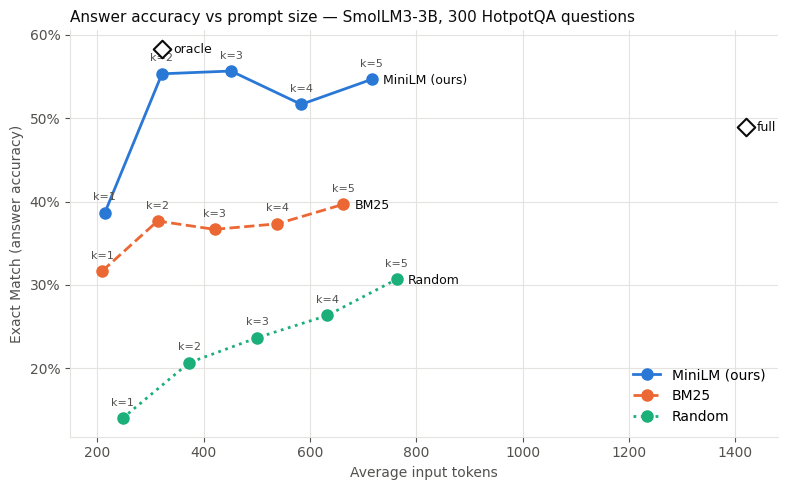

Exact Match by question type:


type,bridge,comparison
condition,,
full,49.4%,47.5%
oracle,59.3%,54.2%
random@1,9.1%,33.9%
bm25@1,27.4%,49.2%
minilm@1,36.5%,47.5%
random@2,15.4%,42.4%
bm25@2,34.9%,49.2%
minilm@2,55.6%,54.2%
random@3,18.7%,44.1%



minilm@3 lost 24 answers that the full prompt got right (96% of them still had all gold paragraphs):


,type,answer,prediction,gold_kept,question
qid,,,,,
5a77b03255429949eeb29f35,bridge,2007,2012,True,Darrell Ward was featured on a reality show that premeried in what year?
5a78fc2155429974737f7935,comparison,A. E. Housman,Housman,True,"Which poet was born first, A. E. Housman or Jaroslav Seifert ?"
5ac170fd55429964131be1fe,bridge,"Paris, France","[2] Paris, France",True,Where was the scientific journal that Émile Verdet was the editorial supervisor for founded?
5ab6840c55429954757d331f,bridge,habitat loss,no,True,The Sabal uresana is threatened by what is the Sierra Madre Occidental?
5a7b18ee554299042af8f6c9,bridge,Westfield Old Orchard,Old Orchard Shopping Center,True,What is the current name of the shopping mall in Skokie developed by Philip M. Klutznick?
5ac05f325542992a796ded03,comparison,yes,No,True,Are Sleeper Agent and Pupil both rock bands?
5add21ab5542992ae4cec49a,bridge,Timothy Carlton and Wanda Ventham,Cumberbatch's parents are Timothy Carlton and Wanda Ventham,True,"Cabin Pressure is a radio sitcom written and created by John Finnemore, the show stars include Benedict Cumberbatch,..."
5ab8f5685542991b5579f096,bridge,1969,1993,False,What year was the thesis supervisor of Jocelyn Bell Burnell awarded the Eddington Medal?
5addfd6f5542997dc7907108,comparison,director,writer,True,What role did both Gene Nelson and Sebastian Gutierrez play in the film industry?


In [30]:
import matplotlib.pyplot as plt

INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
METHODS = [("minilm", "MiniLM (ours)", "#2a78d6", "-"),
           ("bm25", "BM25", "#eb6834", "--"),
           ("random", "Random", "#1baf7a", ":")]

fig, ax = plt.subplots(figsize=(8, 5))
for key, label, color, style in METHODS:
    pts = summary.loc[[f"{key}@{k}" for k in K_VALUES]]
    ax.plot(pts["prompt_tokens"], pts["em"], style, color=color, linewidth=2,
            marker="o", markersize=8, label=label)
    for k, (x, y) in zip(K_VALUES, pts[["prompt_tokens", "em"]].values):
        ax.annotate(f"k={k}", (x, y), textcoords="offset points", xytext=(0, 9),
                    ha="center", fontsize=8, color=MUTED)
    ax.annotate(label, pts[["prompt_tokens", "em"]].values[-1], textcoords="offset points",
                xytext=(8, -3), fontsize=9, color=INK)
for ref in ("full", "oracle"):
    x, y = summary.loc[ref, ["prompt_tokens", "em"]]
    ax.scatter([x], [y], s=80, marker="D", facecolor="white", edgecolor=INK, linewidth=1.5, zorder=3)
    ax.annotate(ref, (x, y), textcoords="offset points", xytext=(8, -3), fontsize=9, color=INK)

ax.set_xlabel("Average input tokens", color=MUTED)
ax.set_ylabel("Exact Match (answer accuracy)", color=MUTED)
ax.set_title(f"Answer accuracy vs prompt size — {LLM_NAME.split('/')[-1]}, {N_EVAL_QUESTIONS} HotpotQA questions",
             color=INK, fontsize=11, loc="left")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.grid(color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.spines[["left", "bottom"]].set_color(GRID)
ax.tick_params(colors=MUTED)
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
fig.savefig(RUN_REPORT_DIR / f"{RUN_NAME}_accuracy_vs_tokens.png", dpi=150)
plt.show()

print("Exact Match by question type:")
display(records.pivot_table(index="condition", columns="type", values="em")
        .reindex(list(CONDITIONS)).map("{:.1%}".format))

full_em = records[records["condition"] == "full"].set_index("qid")["em"]
FAIL_K = 3 if 3 in K_VALUES else K_VALUES[len(K_VALUES) // 2]
mini = records[records["condition"] == f"minilm@{FAIL_K}"].set_index("qid")
lost = mini[(full_em.reindex(mini.index) == 1) & (mini["em"] == 0)]
print(f"\nminilm@{FAIL_K} lost {len(lost)} answers that the full prompt got right "
      f"({lost['gold_kept'].mean():.0%} of them still had all gold paragraphs):")
lost[["type", "answer", "prediction", "gold_kept"]].assign(
    question=lambda d: d.index.map(lambda q: example_by_qid[q]["question"])).head(10)

## 10. Experiment report — record every number, keep only the best model

This last cell turns the run into one row of **`results/experiments.csv`**:

- **every setting** from the Section 0 configuration cell,
- **every metric**: TF-IDF, BM25, MiniLM zero-shot and fine-tuned (test ROC-AUC; precision, recall and F1 of the *relevant* class; all gold paragraphs in top-k), accuracy, the dev score, and for every LLM condition prompt tokens, token reduction, gold kept, EM, F1, answer preservation, fixed / broken answers and tokens per correct answer,
- **every cell timing** (the `⏱` lines) plus the total, and the **peak VRAM** of MiniLM training and of LLM generation.

A run with the same `RUN_NAME` replaces its old row, so re-running never duplicates results. Together with the executed notebook of each run (`experiments/<run>.ipynb`), the per-run answers and the plot (`results/runs/`), this is the complete record of the run.

**Best-model bookkeeping.** The run's dev score (all gold paragraphs in the top-`BEST_METRIC_K`) is compared with `models/minilm-hotpotqa-best/best_run.json`. If it is higher, this run's MiniLM becomes the new best model; otherwise it is discarded. Re-running the best run itself always refreshes its model, so the kept model matches its recorded metrics. Either way the run folder is deleted, so only one model — the best — is ever kept on disk. Because selection uses the **dev** set, the test scores of the best run remain an unbiased estimate.

The cell ends with a side-by-side table of every run so far; the best model's row is marked.

In [31]:
from uuid import uuid4

cell_t0 = time.time()
PARAM_NAMES = ["SEED", "SAMPLE_FRAC", "TEST_FRAC", "DEV_FRAC", "BM25_FRAC", "MAX_LENGTH", "TRAIN_BATCH_SIZE",
               "EVAL_BATCH_SIZE", "EPOCHS", "LEARNING_RATE", "WARMUP_FRAC", "TRAIN_FRAC", "BEST_METRIC_K", "LLM_NAME",
               "N_EVAL_QUESTIONS", "K_VALUES", "GEN_BATCH_SIZE", "GEN_MAX_BATCH_TOKENS", "MAX_NEW_TOKENS",
               "SENT_MAX_LENGTH"]
params = {name: globals()[name] for name in PARAM_NAMES}
params["K_VALUES"] = " ".join(map(str, K_VALUES))

# Select the best MiniLM across runs using dev-set performance.
# If this run should become the best, prepare a complete copy before
# replacing the existing best model, keeping a backup during promotion.
# When rerunning an already promoted winning run whose RUN_DIR was
# removed, preserve the saved best model and continue writing the report.


best_file = BEST_DIR / "best_run.json"
best = json.loads(best_file.read_text()) if best_file.exists() else None

should_promote = (
    best is None
    or best["run"] == RUN_NAME
    or REPORT["dev_metric"] > best["dev_metric"]
)

if not RUN_DIR.exists():
     # A successful promotion removes RUN_DIR. Rerunning this cell
     # preserves the best model that was already saved.
    if best is None or best["run"] != RUN_NAME:
        raise FileNotFoundError(f"Run model is missing: {RUN_DIR}")

    print("Run model already promoted; keeping the saved best model.")

elif should_promote:
    # Unique sibling folders avoid collisions with earlier attempts.
    suffix = uuid4().hex
    staging = BEST_DIR.with_name(f"{BEST_DIR.name}.staging-{suffix}")
    backup = BEST_DIR.with_name(f"{BEST_DIR.name}.backup-{suffix}")

    new_best = {
        "run": RUN_NAME,
        "dev_metric": REPORT["dev_metric"],
        **params,
    }

    # Prepare the complete model and its metadata before touching
    # the existing best model. A copy failure leaves it just as it was.

    shutil.copytree(RUN_DIR, staging)
    (staging / "best_run.json").write_text(
        json.dumps(new_best, indent=2)
    )

    # Keeping the previous best available until promotion succeeds.

    had_best = BEST_DIR.exists()
    if had_best:
        BEST_DIR.rename(backup)

    try:
        staging.rename(BEST_DIR)
    except Exception:
        # We restore the previous best if the new folder cannot be promoted.
        if had_best:
            backup.rename(BEST_DIR)
        raise

    best = new_best
    shutil.rmtree(backup, ignore_errors=True)
    print(f"Saved best model: {RUN_NAME}")

else:
    print(f"{RUN_NAME} did not beat {best['run']}.")

# We remove the temporary run model only after promotion succeeds
# or the run is confirmed not to improve on the current best.

shutil.rmtree(RUN_DIR, ignore_errors=True)

TIMINGS["total"] = round(time.time() - NOTEBOOK_T0, 1)
row = {"run": RUN_NAME, "finished": time.strftime("%Y-%m-%d %H:%M"), **params, **REPORT,
       **{f"time_{label}": secs for label, secs in TIMINGS.items()}}
exp_path = RESULTS_DIR / "experiments.csv"
experiments = pd.read_csv(exp_path) if exp_path.exists() else pd.DataFrame(columns=["run"])
experiments = pd.concat([experiments[experiments["run"] != RUN_NAME], pd.DataFrame([row])], ignore_index=True)
experiments["best_model"] = experiments["run"] == best["run"]
experiments.to_csv(exp_path, index=False)
print(f"Saved run {RUN_NAME} to {exp_path.resolve()} ({len(experiments)} runs recorded)\n")

view = {"run": "run", "TRAIN_BATCH_SIZE": "batch", "LEARNING_RATE": "lr", "EPOCHS": "epochs", "MAX_LENGTH": "max len",
        "dev_metric": f"dev top-{BEST_METRIC_K}", "ft_roc_auc": "test ROC-AUC", "ft_accuracy": "test accuracy",
        "ft_precision": "test precision", "ft_recall": "test recall", "ft_f1": "test F1", "ft_top2": "test top-2",
        "ft_top3": "test top-3", "minilm@2_em": "LLM EM @2", "minilm@2_f1": "LLM F1 @2",
        "minilm@2_token_reduction": "tokens removed @2", "minilm@2_answer_preservation": "answers kept @2",
        "minilm@2_tokens_per_correct": "tokens/correct @2", "full_em": "LLM EM full",
        "peak_vram_llm_gb": "peak VRAM (GB)", "time_total": "total (min)", "best_model": "best"}
table = experiments[[c for c in view if c in experiments]].rename(columns=view)
if "lr" in table:
    table["lr"] = table["lr"].map("{:.0e}".format)  # round(4) below would show 2e-5 as 0.0
if "total (min)" in table:
    table["total (min)"] = (table["total (min)"] / 60).round(1)
log_time("10. Experiment report", cell_t0)
table.round(8)

Saved best model: r5_2epochs
Saved run r5_2epochs to C:\Users\Retro\Documents\Prompt Optimizer Project NLP\prompt-compression-project\results\experiments.csv (5 runs recorded)

⏱ 10. Experiment report: 0.1s


,run,batch,lr,epochs,max len,dev top-2,test ROC-AUC,test accuracy,test precision,test recall,...,test top-3,LLM EM @2,LLM F1 @2,tokens removed @2,answers kept @2,tokens/correct @2,LLM EM full,peak VRAM (GB),total (min),best
0,r1_baseline,32.0,2e-05,1.0,256.0,0.874585,0.986577,0.948160,0.832513,0.929309,...,0.946502,0.546667,0.666617,0.763432,0.812500,585.829268,0.48,8.509353,22.7,False
1,r2_bs16,16.0,2e-05,1.0,256.0,0.885568,0.987257,0.955799,0.879539,0.904144,...,0.948444,0.550000,0.671617,0.763316,0.819444,582.733333,0.48,8.484528,23.9,False
2,r3_bs64_lr4e-5,64.0,4e-05,1.0,256.0,0.885824,0.988123,0.947281,0.821871,0.942185,...,0.950743,0.550000,0.669951,0.764226,0.826389,580.133333,0.48,8.401577,16.6,False
3,r4_len384,32.0,2e-05,1.0,384.0,0.879183,0.986663,0.948967,0.838141,0.924991,...,0.946809,0.550000,0.669951,0.763672,0.819444,581.381818,0.48,8.263495,22.2,False
4,r5_2epochs,32.0,2e-05,2.0,256.0,0.892465,0.989303,0.956662,0.866209,0.927929,...,0.954678,0.553333,0.667649,0.762830,0.809524,580.825301,0.49,8.538285,34.3,True
